<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-01-augmentation.ipynb" target="_parent"><img src="img/colab-badge.svg" alt="Open In Colab"/></a>

---
title: "Data Augmentation"
---

# Introduction to the coding tools

# The `sklearn` estimator interface

An **estimator** is a scikit-learn object that learns from data.

- Estimators follow the same API

```python
model = Estimator(parameters) # set the algorithm and its hyperparameters
model.fit(X_train, y_train) # train the model (i.e., learn the internal parameters)
predictions = model.predict(X_test) # make predictions on new data
```



# Why pipelines matter

A machine-learning pipeline is rarely just a classifier. 

- A real workflow often includes missing-value handling, scaling, categorical encoding, feature selection, resampling, *and then the final estimator*.

`sklearn.pipeline.Pipeline` packages these steps into one object with the same `fit`, and `predict` interface.


```python
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
pipeline = Pipeline([ # set the pipeline and its hyperparameters
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000)),
])
pipeline.fit(X_train, y_train) # train the pipeline
pipeline.predict(X_test) # make predictions on new data
```

A pipeline chains transformers and a final estimator:

- Every preprocessing step must be learned only from the training data. *Why*?
    - `StandardScaler` is fitted on `X_train` only.
- The test set is transformed using the training-set scaling parameters.


# Recalling validation and cross validation

::::{.columns}
:::{.column width="50%"}
When evaluating different hyperparameters for estimators, we cannot do it on the test set, as this would lead to data leakage. 

- Hyperparameters can be tweaked until the estimator performs optimally, but knowledge about the test set "leak" into the model (= *cheating*)
- To solve this problem, a part of the train set can be held out as a so-called "validation set"
- Training on the training set, hyperparameter tuning on the validation set, and final evaluation on the test set.
- By partitioning the available data into three sets, we (1) reduce the number of samples which can be used for learning, and (2) the results can depend on a particular random choice for (train, validation) sets.

Cross-validation is a solution to this problem 
:::
:::{.column width="50%"}
![[Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)](https://scikit-learn.org/stable/_images/grid_search_cross_validation.png)
:::
::::


# Hyper-parameter optimization with cross-validation

HPO (e.g., `GridSearchCV`) trains and evaluates many pipeline configurations using cross-validation. *Why*?

- Pipeline hyperparameters are addressed with as `step_name__parameter_name`.
- Each fold fits preprocessing and the classifier only on the training part of that fold.

```python
from sklearn.model_selection import GridSearchCV, StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # why cross validation?
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"],
}
search = GridSearchCV( # alternative to GridSeach?
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1", # why f1?
    cv=cv,
)
search.fit(X_train, y_train)
search.best_params_
```


# Data augmentation

# The imbalanced classification problem

Many important binary classification problems have one class that is much rarer than the other.

<details>
<summary>Examples</summary>
Fraud detection, medical diagnosis, safety incidents, customer churn, credit default, and equipment failures.
</details>

We call the frequent class the **majority class** and the rare class the **minority class**.

- Usually, the minority class is the positive class: `1`.

When classes are imbalanced, **accuracy can be misleading**. *Why?*

<details>
<summary>Answer</summary>
If only 5% of customers churn, a classifier that always predicts "no churn" reaches 95% accuracy while finding no churners at all.
</details>

# High accuracy can hide every missed positive

In [ ]:
#| echo: false

import importlib.util
import subprocess
import sys

if importlib.util.find_spec("imblearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.datasets import fetch_datasets
from imblearn.over_sampling import ADASYN, BorderlineSMOTE, RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Patch, Rectangle
from sklearn.base import clone
from sklearn.datasets import make_classification
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
BLUE, ORANGE, GREEN, RED, GRAY = "tab:blue", "tab:orange", "tab:green", "tab:red", "tab:gray"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=plt.get_cmap("tab10").colors),
    "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "savefig.facecolor": "white", "svg.fonttype": "none",
})


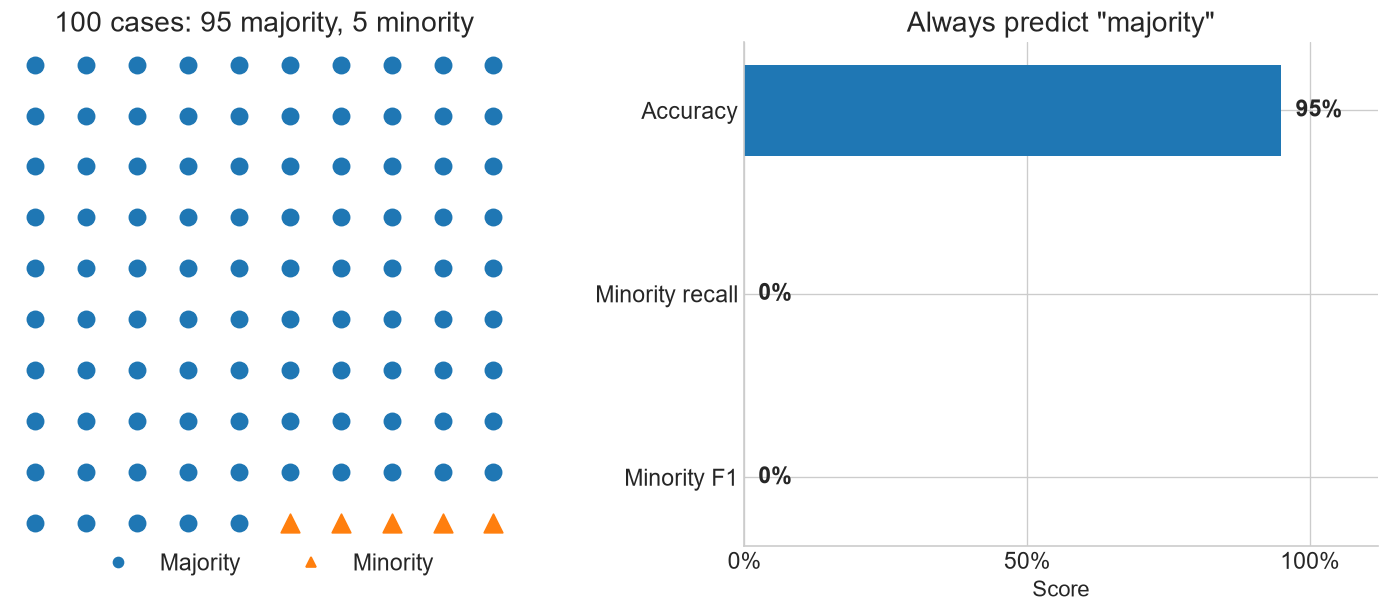

In [ ]:
#| echo: false
#| fig-height: 4.7
# Synthetic data illustrate the mechanism, not model performance.
def plot_accuracy_trap():
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
    x, y = np.meshgrid(np.arange(10), np.arange(10))
    minority = np.arange(100) >= 95
    ax = axes[0]
    ax.scatter(x.ravel()[~minority], y.ravel()[~minority], s=95, c=BLUE)
    ax.scatter(x.ravel()[minority], y.ravel()[minority], s=125, c=ORANGE, marker="^")
    ax.set(title="100 cases: 95 majority, 5 minority", aspect="equal")
    ax.invert_yaxis()
    ax.axis("off")
    ax.legend(handles=[
        Line2D([], [], marker="o", ls="", color=BLUE, label="Majority"),
        Line2D([], [], marker="^", ls="", color=ORANGE, label="Minority"),
    ], loc="lower center", bbox_to_anchor=(.5, -.10), ncol=2)
    ax = axes[1]
    bars = ax.barh(["Accuracy", "Minority recall", "Minority F1"], [.95, 0, 0],
                   color=[BLUE, ORANGE, RED], height=.5)
    ax.invert_yaxis()
    ax.set(xlim=(0, 1.12), title='Always predict "majority"', xlabel="Score")
    ax.set_xticks([0, .5, 1], ["0%", "50%", "100%"])
    for bar, label in zip(bars, ["95%", "0%", "0%"]):
        ax.text(bar.get_width() + .025, bar.get_y() + bar.get_height()/2, label, va="center", weight="bold")
    plt.show()

plot_accuracy_trap()


# How can we handle class imbalance?

# Find better metrics

Depending on the case study, optimize different metrics while training the model:

- **Precision**: among predicted positives, how many were actually positive?
- **Recall** or sensitivity: among actual positives, how many did we find?
- **Specificity**: among actual negatives, how many did we correctly reject?
- **F1 score**: harmonic mean of precision and recall.

# Methods for handling imbalance

- **Class weights**: make minority-class errors more expensive.
- **Sampling**: random (?), statified (?), **undersampling**, and **oversampling**.
- **SMOTE and variants**: synthesize minority examples.

# Sampling methods

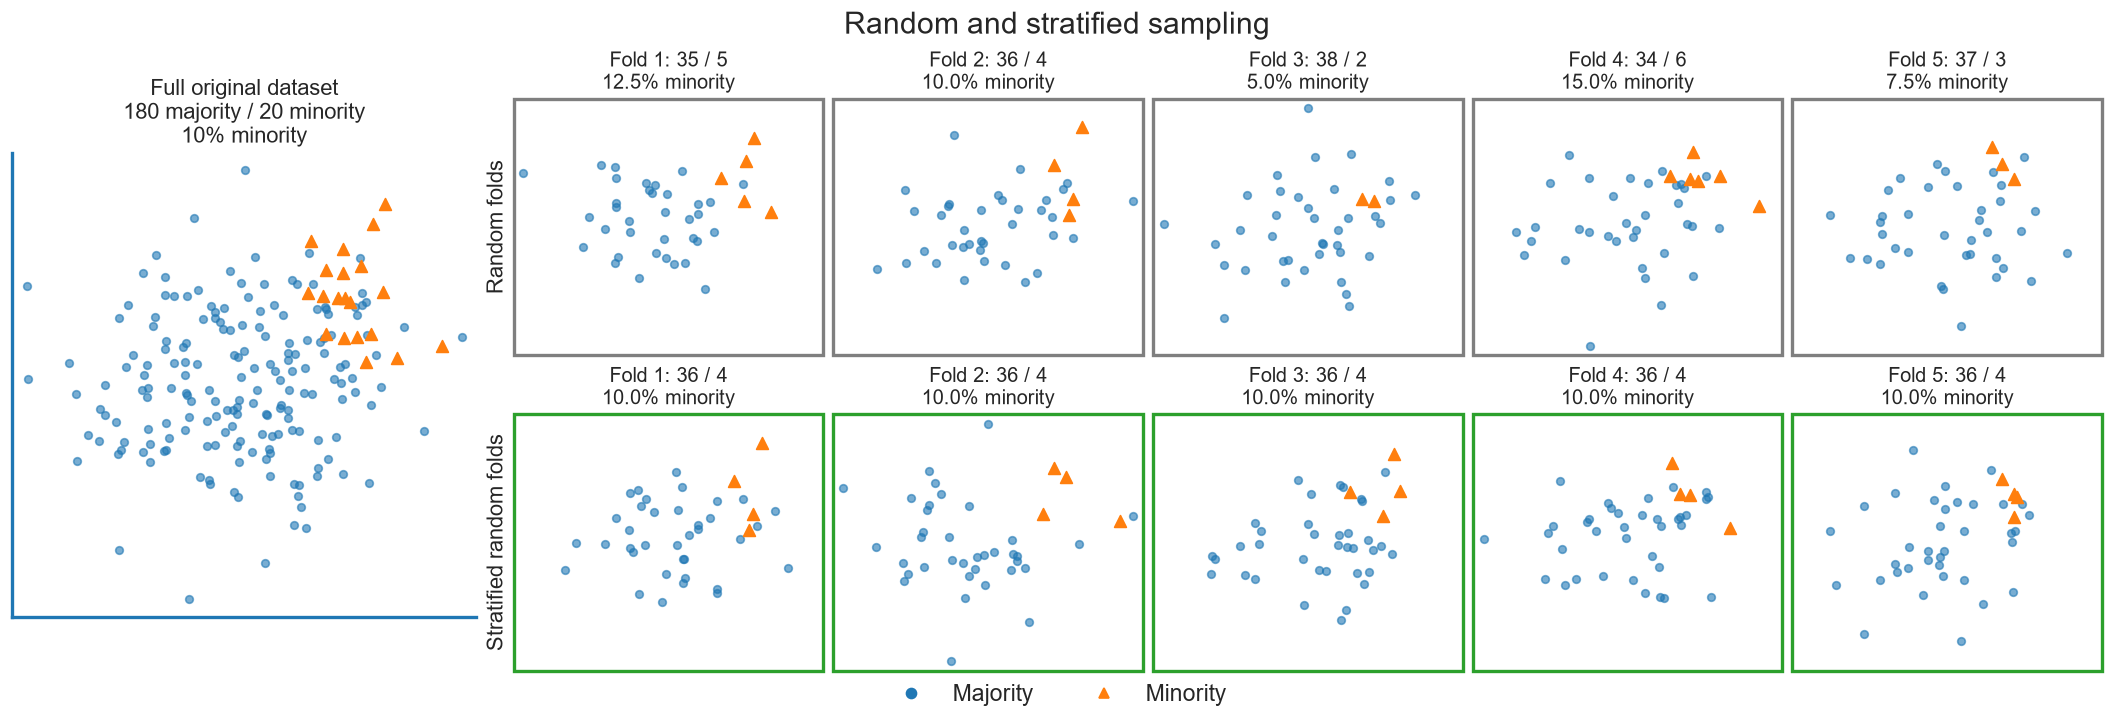

In [ ]:
#| echo: false
#| fig-height: 5.0

def plot_splitting_preserves_imbalance():

    rng = np.random.default_rng(19)
    # Identical source data and 2D coordinates for both splitting strategies.
    points = np.vstack([rng.normal([0, 0], [1.1, .85], size=(180, 2)),
                        rng.normal([1.5, 1], [.45, .45], size=(20, 2))])
    labels = np.r_[np.zeros(180, dtype=int), np.ones(20, dtype=int)]
    splits = [KFold(n_splits=5, shuffle=True, random_state=7),
              StratifiedKFold(n_splits=5, shuffle=True, random_state=7)]
    fig = plt.figure(figsize=(17.5, 6), layout='constrained')
    grid = fig.add_gridspec(2, 6, width_ratios=[1.5, 1, 1, 1, 1, 1])
    original_ax = fig.add_subplot(grid[:, 0])
    original_ax.scatter(*points[labels == 0].T, color=BLUE, s=21, alpha=.6)
    original_ax.scatter(*points[labels == 1].T, color=ORANGE, marker='^', s=50, zorder=3)
    original_ax.set_title('Full original dataset\n180 majority / 20 minority\n10% minority', fontsize=13)
    original_ax.set(xlim=(points[:, 0].min()-.2, points[:, 0].max()+.2),
                    ylim=(points[:, 1].min()-.2, points[:, 1].max()+.2), xticks=[], yticks=[])
    original_ax.set_box_aspect(1)
    for spine in original_ax.spines.values():
        spine.set_color(BLUE)
        spine.set_linewidth(2)
    axes = np.array([[fig.add_subplot(grid[row, fold+1], sharex=original_ax, sharey=original_ax)
                      for fold in range(5)] for row in range(2)])
    for row, splitter in enumerate(splits):
        validation_rows = []
        for fold, (train_idx, valid_idx) in enumerate(splitter.split(points, labels)):
            validation_rows.extend(valid_idx)
            ax = axes[row, fold]
            X_fold, y_fold = points[valid_idx], labels[valid_idx]
            minority = int(y_fold.sum())
            majority = len(y_fold) - minority
            if row == 1:
                assert minority == 4 and int(labels[train_idx].sum()) == 16
            ax.scatter(*X_fold[y_fold == 0].T, color=BLUE, s=21, alpha=.6)
            ax.scatter(*X_fold[y_fold == 1].T, color=ORANGE, marker='^', s=50, zorder=3)
            # Frames represent fold membership, NOT a partition of feature space.
            ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes,
                                  fill=False, edgecolor=GREEN if row else GRAY,
                                  linewidth=2, clip_on=False))
            ax.set_title(f'Fold {fold+1}: {majority} / {minority}\n{minority/len(y_fold):.1%} minority', fontsize=12)
            ax.set(xlim=(points[:, 0].min()-.2, points[:, 0].max()+.2),
                   ylim=(points[:, 1].min()-.2, points[:, 1].max()+.2), xticks=[], yticks=[])
            for spine in ax.spines.values():
                spine.set_visible(False)
        assert sorted(validation_rows) == list(range(len(points)))
    axes[0, 0].set_ylabel('Random folds', fontsize=13)
    axes[1, 0].set_ylabel('Stratified random folds', fontsize=13)
    fig.suptitle('Random and stratified sampling', fontsize=18)
    fig.legend(handles=[
        Line2D([], [], marker='o', ls='', color=BLUE, label='Majority'),
        Line2D([], [], marker='^', ls='', color=ORANGE, label='Minority'),
    ], loc='outside lower center', ncol=2)
    plt.show()

plot_splitting_preserves_imbalance()


# How resampling changes the training set

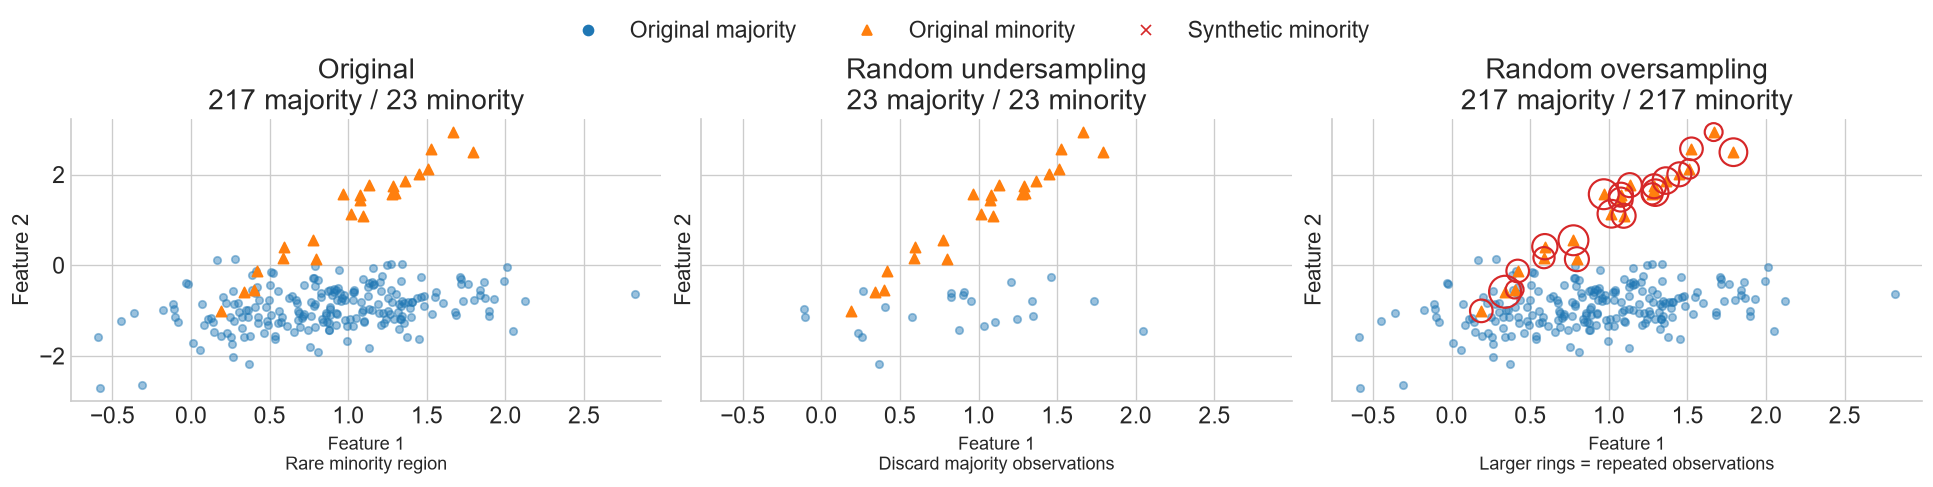

In [ ]:
#| echo: false
#| fig-height: 4.7
# Synthetic data illustrate the mechanism, not model performance.
def plot_resampling():
    X, y = make_classification(n_samples=240, n_features=2, n_informative=2,
        n_redundant=0, n_clusters_per_class=1, weights=[.9, .1],
        class_sep=.9, flip_y=.02, random_state=42)
    methods = [
        ("Original", None, "Rare minority region"),
        ("Random undersampling", RandomUnderSampler(random_state=42), "Discard majority observations"),
        ("Random oversampling", RandomOverSampler(random_state=42), "Larger rings = repeated observations"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True, layout="constrained")
    for ax, (name, sampler, note) in zip(axes.flat, methods):
        xr, yr = (X, y) if sampler is None else sampler.fit_resample(X, y)
        # Undersamplers select rows; their returned order is not an original/new mask.
        n_original = len(xr) if isinstance(sampler, RandomUnderSampler) else len(X)
        original = np.arange(len(xr)) < n_original
        ax.scatter(*xr[(yr == 0) & original].T, s=20, c=BLUE, alpha=.45)
        ax.scatter(*xr[(yr == 1) & original].T, s=38, c=ORANGE, marker="^", zorder=3)
        if isinstance(sampler, RandomOverSampler):
            indices, counts = np.unique(sampler.sample_indices_, return_counts=True)
            repeated = counts > 1
            ax.scatter(*X[indices[repeated]].T, s=counts[repeated]*23,
                       facecolors="none", edgecolors=RED, linewidths=1.3, zorder=4)
        elif sampler is not None and not isinstance(sampler, RandomUnderSampler):
            ax.scatter(*xr[~original].T, s=23, c=RED, marker="x", alpha=.65)
        ax.set_title(f"{name}\n{np.sum(yr == 0)} majority / {np.sum(yr == 1)} minority")
        ax.set_xlabel(f"Feature 1\n{note}", fontsize=11)
        ax.set_ylabel("Feature 2")
    fig.legend(handles=[
        Line2D([], [], marker="o", ls="", color=BLUE, label="Original majority"),
        Line2D([], [], marker="^", ls="", color=ORANGE, label="Original minority"),
        Line2D([], [], marker="x", ls="", color=RED, label="Synthetic minority"),
    ], loc="outside upper center", ncol=3)
    plt.show()

plot_resampling()


# Data augmentation

*Data augmentation* applies label-preserving transformations: image rotations, sensor noise, audio crops, or text perturbations.


![Data augmentation in MNIST](https://www.researchgate.net/publication/372609466/figure/fig4/AS:11431281177302326@1690424595252/Examples-of-data-transformations-applied-in-the-MNIST-dataset-Each-of-these-generated_W640.jpg)


# What about tabular data?

*SMOTE* [@chawla2002smote] creates tabular rows by interpolation in feature space.

- Simple intuition: fill sparse minority regions instead of duplicating existing minority-class observations. 
- Risk: interpolation may create impossible records: could the generated record exist in the real data?

For a minority point $x_i$, it selects a nearby minority point $x_j$ and creates: $x_{new} = x_i + \lambda * (x_j - x_i)$

# SMOTE: move toward a minority neighbor

Each cross (x) uses a different interpolation weight $\lambda$.

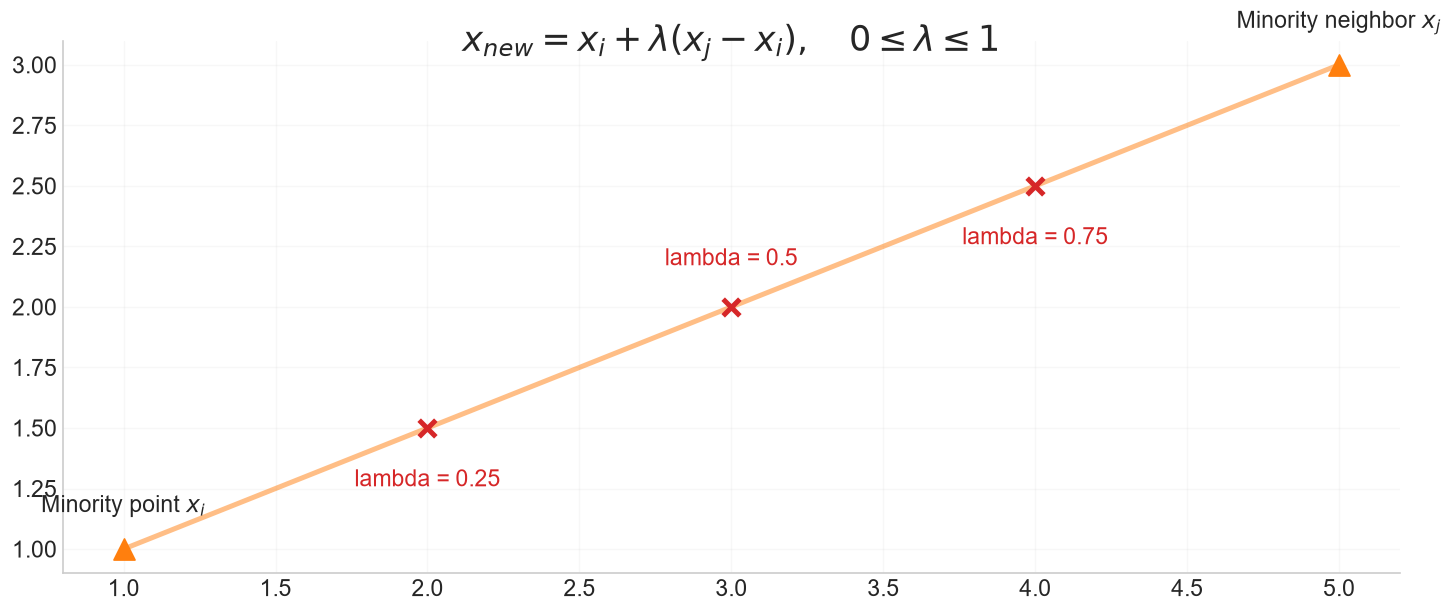

In [ ]:
#| echo: false
#| fig-height: 4.7
def plot_smote_segment():
    fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
    a, b = np.array([1., 1.]), np.array([5., 3.])
    ax.plot(*np.array([a, b]).T, color=ORANGE, lw=3, alpha=.5)
    ax.scatter(*np.array([a, b]).T, s=160, c=ORANGE, marker="^", zorder=3)
    for lam, offset in [(.25, -35), (.5, 25), (.75, -35)]:
        p = a + lam * (b-a)
        ax.scatter(*p, s=100, c=RED, marker="x", linewidth=3, zorder=4)
        ax.annotate(f"lambda = {lam:g}", p, xytext=(0, offset),
                    textcoords="offset points", ha="center", color=RED)
    ax.annotate("Minority point $x_i$", a, xytext=(0, 22), textcoords="offset points", ha="center")
    ax.annotate("Minority neighbor $x_j$", b, xytext=(0, 22), textcoords="offset points", ha="center")
    ax.text(.5, .98, r"$x_{new} = x_i + \lambda (x_j - x_i),\quad 0 \leq \lambda \leq 1$", transform=ax.transAxes, ha="center", fontsize=21)
    ax.grid(alpha=.15)
    plt.show()

plot_smote_segment()


# Why scaling before SMOTE?

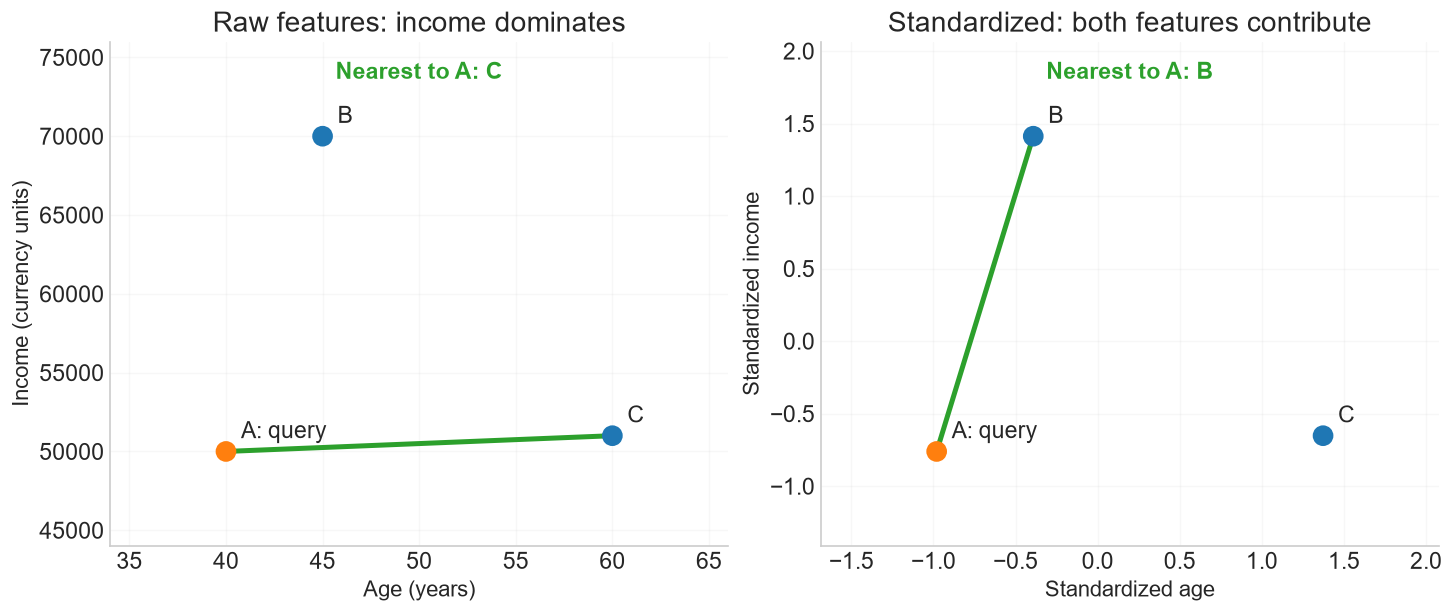

In [ ]:
#| echo: false
#| fig-height: 4.7
# Synthetic data illustrate the mechanism, not model performance.
def plot_scaling_neighbors():
    # Same observations and Euclidean distance, before and after standardization.
    X = np.array([[40, 50000], [45, 70000], [60, 51000]], dtype=float)
    scaled = StandardScaler().fit_transform(X)
    assert np.argmin(np.linalg.norm(X[1:] - X[0], axis=1)) == 1
    assert np.argmin(np.linalg.norm(scaled[1:] - scaled[0], axis=1)) == 0
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
    for ax, points, title in zip(axes, [X, scaled],
                                ["Raw features: income dominates", "Standardized: both features contribute"]):
        distances = np.linalg.norm(points[1:] - points[0], axis=1)
        nearest = 1 + distances.argmin()
        ax.scatter(*points.T, c=[ORANGE, BLUE, BLUE], s=130, zorder=3)
        for i, label in enumerate(["A: query", "B", "C"]):
            ax.annotate(label, points[i], xytext=(9, 8), textcoords="offset points")
        ax.plot(*points[[0, nearest]].T, color=GREEN, lw=3, zorder=2)
        ax.margins(.3)
        ax.set_title(title)
        ax.text(.5, .96, f"Nearest to A: {'ABC'[nearest]}", transform=ax.transAxes,
                ha="center", va="top", color=GREEN, weight="bold")
        ax.grid(alpha=.15)
    axes[0].set(xlabel="Age (years)", ylabel="Income (currency units)")
    axes[1].set(xlabel="Standardized age", ylabel="Standardized income")
    plt.show()

plot_scaling_neighbors()


# Borderline-SMOTE: which points are in danger?

**Borderline-SMOTE** focuses on minority observations near the class boundary [@han2005borderline].

- These are the points a classifier is most likely to confuse with the majority class.
- This can help boundary recall, but noisy or mislabeled boundary points can be reinforced.

For each minority point, find `m_neighbors` nearest training rows from both classes.

- Count majority neighbors as $a_i$ out of $m$.
- **Safe:** $a_i < \frac{m}{2}$; **danger:** $\frac{m}{2} \leq a_i < m$; **noise:** $a_i=m$.
    - Noise is a neighborhood label, not proof of an incorrect class.
- Choose danger points as generation seeds.
    - `k_neighbors` then finds minority neighbors for interpolation.

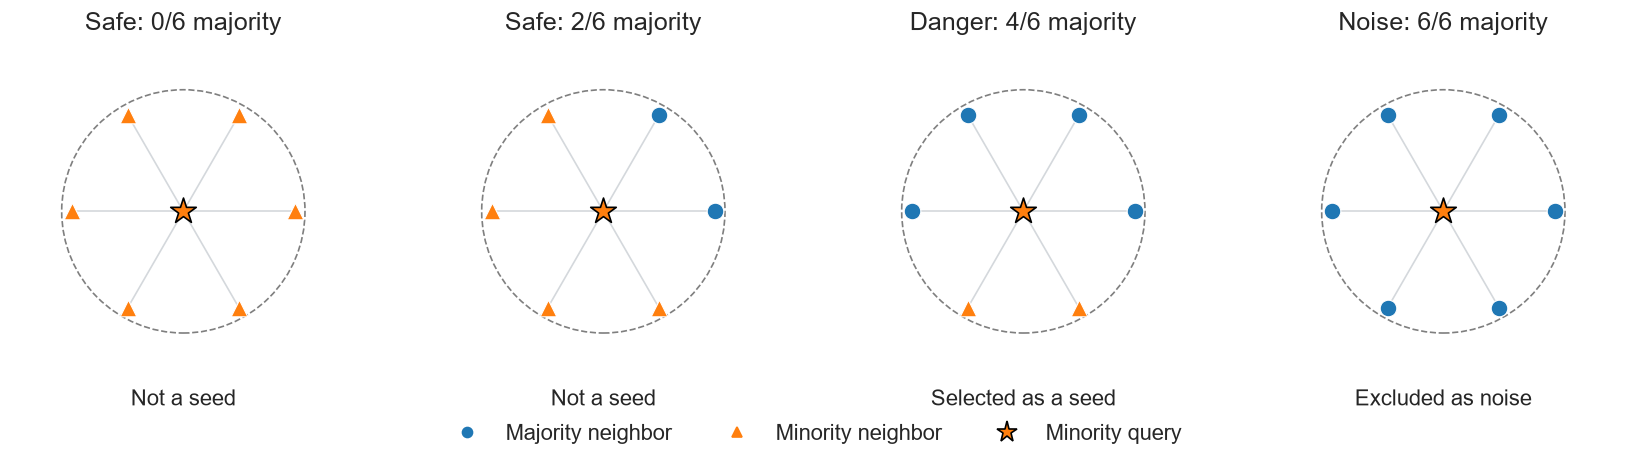

In [ ]:
#| echo: false
#| fig-height: 4.7
#| out-height: "400px"

def make_hard_region_example():

    # Four isolated seven-point groups with known all-class neighbor counts.
    # All features already use the same scale; every query is a training row.
    rng = np.random.default_rng(42)
    angles = np.arange(6) * (2 * np.pi / 6)
    offsets = 0.65 * np.column_stack([np.cos(angles), np.sin(angles)])
    points, labels, queries = [], [], []
    for group, majority_count in enumerate([0, 2, 4, 6]):
        center = np.array([3.0 * group, 0.0])
        queries.append(7 * group)
        points.append(np.vstack([center, center + offsets]))
        labels.extend([1] + [0] * majority_count + [1] * (6 - majority_count))
    # Keep class 1 globally rare without changing the four local neighborhoods.
    points.append(rng.uniform([2.5, -4.5], [6.5, -3.5], size=(60, 2)))
    labels.extend([0] * 60)
    X_example, y_example = np.vstack(points), np.asarray(labels)
    minority_indices = np.flatnonzero(y_example == 1)
    query_positions = np.searchsorted(minority_indices, queries)
    neighbors = NearestNeighbors(n_neighbors=7).fit(X_example).kneighbors(
        X_example[minority_indices], return_distance=False,
    )[:, 1:]
    majority_counts = (y_example[neighbors] == 0).sum(axis=1)
    danger = (majority_counts >= 3) & (majority_counts < 6)
    sampler = BorderlineSMOTE(m_neighbors=6, k_neighbors=2, kind='borderline-1', random_state=42)
    X_resampled, _ = sampler.fit_resample(X_example, y_example)
    np.testing.assert_array_equal(majority_counts[query_positions], [0, 2, 4, 6])
    np.testing.assert_array_equal(
        np.sort(sampler.in_danger_indices[1]), minority_indices[danger],
    )
    assert danger.sum() == 3 and len(X_resampled) - len(X_example) == 56
    return dict(X=X_example, y=y_example, minority_indices=minority_indices,
                queries=np.asarray(queries), query_positions=query_positions,
                neighbors=neighbors, majority_counts=majority_counts)

def plot_borderline_hard_regions(example):

    with plt.rc_context({'font.size': 13, 'axes.titlesize': 15}):
        fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), layout='constrained')
        statuses = ['Safe', 'Safe', 'Danger', 'Noise']
        notes = ['Not a seed', 'Not a seed', 'Selected as a seed', 'Excluded as noise']
        X_example, y_example = example['X'], example['y']
        for panel, (ax, query, position) in enumerate(zip(
                axes, example['queries'], example['query_positions'])):
            center = X_example[query]
            neighbors = example['neighbors'][position]
            count = example['majority_counts'][position]
            for neighbor in neighbors:
                ax.plot(*X_example[[query, neighbor]].T, color='#D4D8DC', linewidth=1, zorder=0)
            for label, marker, color in [(0, 'o', BLUE), (1, '^', ORANGE)]:
                selected = neighbors[y_example[neighbors] == label]
                ax.scatter(*X_example[selected].T, s=100, marker=marker,
                           color=color, edgecolors='white', linewidths=.7, zorder=3)
            radius = np.linalg.norm(X_example[neighbors] - center, axis=1).max() + .06
            ax.add_patch(Circle(center, radius, fill=False, linestyle='--', color=GRAY))
            ax.scatter(*center, marker='*', s=260, color=ORANGE, edgecolor='black', linewidth=1, zorder=4)
            ax.set(xlim=(center[0] - 1, center[0] + 1), ylim=(-1, 1),
                   xticks=[], yticks=[], aspect='equal',
                   title=f'{statuses[panel]}: {count}/6 majority', xlabel=notes[panel])
            for spine in ax.spines.values():
                spine.set_visible(False)
        fig.legend(handles=[
            Line2D([], [], marker='o', ls='', color=BLUE, label='Majority neighbor'),
            Line2D([], [], marker='^', ls='', color=ORANGE, label='Minority neighbor'),
            Line2D([], [], marker='*', markersize=13, ls='', color=ORANGE, markeredgecolor='black', label='Minority query'),
        ], loc='outside lower center', ncol=3)
        plt.show()

hard_region_example = make_hard_region_example()
plot_borderline_hard_regions(hard_region_example)


# ADASYN

**ADASYN** estimates local difficulty from nearest neighbors [@he2008adasyn].

- The method shifts attention toward hard minority regions, which can be useful or risky depending on label noise and class overlap.
- Minority observations surrounded by many majority observations receive larger sampling weights.
    - Creates more synthetic minority examples around locally difficult observations.

How?

- Count majority labels among the $k$ nearest training neighbors of each minority point.
- Define difficulty as $r_i=\frac{a_i}{k}$.
- For a budget of $G$ new rows, allocate $g_i \approx G \frac{r_i}{\sum_j r_j}$ to seed $i$ (spread $G$ over all minority seeds).
    - 0-majority neighbors gives zero allocation; a larger majority fraction gives a larger allocation.
- ADASYN has no separate noise exclusion, so an isolated minority point can receive the largest weight.

# ADASYN: compare the same four minority queries

The 16 minority seeds share 56 new rows; the plots show only the four starred queries from the previous example.


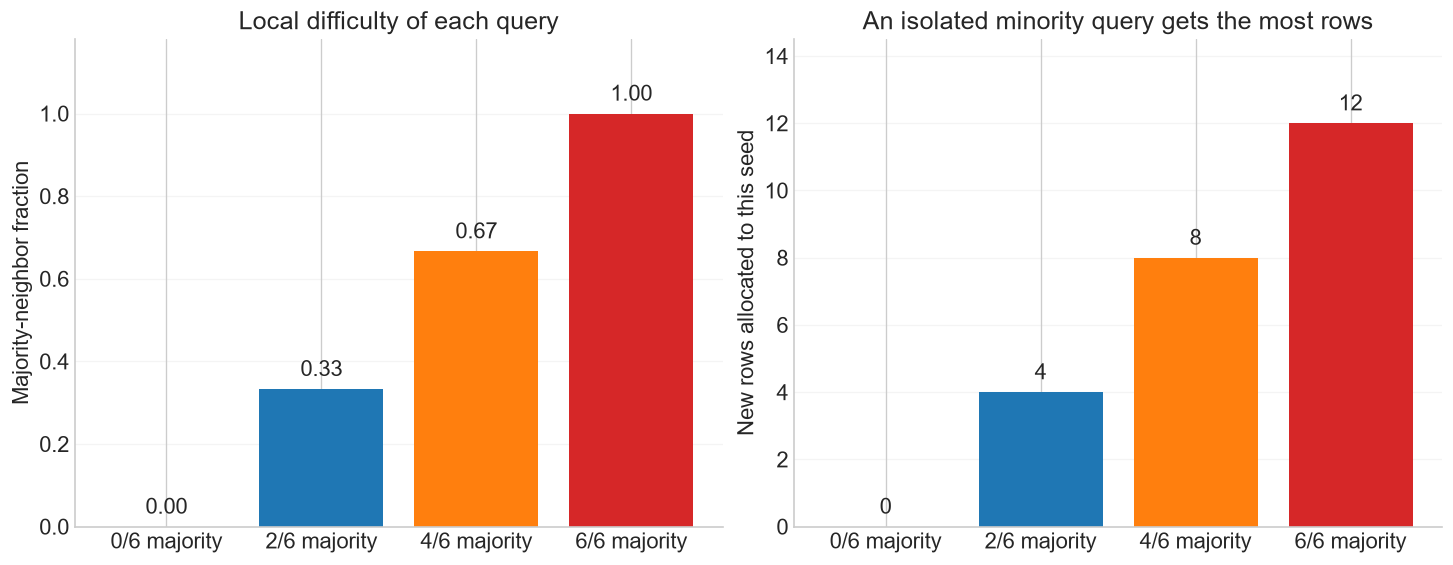

In [ ]:
#| echo: false
#| fig-height: 4.7
#| out-height: "400px"

def plot_adasyn_hard_regions(example):

    X_example, y_example = example['X'], example['y']
    difficulty = example['majority_counts'] / 6
    sampler = ADASYN(n_neighbors=6, random_state=42)
    X_resampled, y_resampled = sampler.fit_resample(X_example, y_example)
    budget = int(sampler.sampling_strategy_[1])
    quotas = np.rint(budget * difficulty / difficulty.sum()).astype(int)
    positions = example['query_positions']
    query_difficulty, query_quotas = difficulty[positions], quotas[positions]
    np.testing.assert_array_equal(query_quotas, [0, 4, 8, 12])
    assert budget == quotas.sum() == len(X_resampled) - len(X_example) == 56
    assert np.array_equal(np.bincount(y_resampled), [72, 72])

    with plt.rc_context({'font.size': 13, 'axes.titlesize': 15}):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
        colors = [GREEN, BLUE, ORANGE, RED]
        labels = ['0/6 majority', '2/6 majority', '4/6 majority', '6/6 majority']
        bars = axes[0].bar(np.arange(4), query_difficulty, color=colors)
        axes[0].bar_label(bars, fmt='%.2f', padding=5)
        axes[0].set(xticks=range(4), xticklabels=labels, ylim=(0, 1.18),
                    ylabel='Majority-neighbor fraction', title='Local difficulty of each query')
        bars = axes[1].bar(np.arange(4), query_quotas, color=colors)
        axes[1].bar_label(bars, fmt='%d', padding=5)
        axes[1].set(xticks=range(4), xticklabels=labels, ylim=(0, 14.5),
                    ylabel='New rows allocated to this seed', title='An isolated minority query gets the most rows')
        for ax in axes:
            ax.set_axisbelow(True)
            ax.grid(axis='y', alpha=.2)
        plt.show()

plot_adasyn_hard_regions(hard_region_example)


# When should we try each sampler?

| Method | Worth trying when | Main risk |
|---|---|---|
| SMOTE | Minority regions are broadly undersampled. | Interpolation bridges clusters or outliers. |
| Borderline-SMOTE | Reliable labels define a difficult class boundary. | Boundary noise is reinforced. |
| ADASYN | Difficulty varies across regions and labels are reliable. | Outliers attract too many new rows. |

The classifier, feature scaling, neighbor count, and class overlap can change the ranking.

- [Sampling mechanisms and failure cases](https://imbalanced-learn.org/stable/over_sampling.html#ill-posed-examples)


# A controlled comparison across four conditions

The plots show the observed training labels for seed 42; all features use comparable units.

- Each dataset has 1,000 training rows and 3,000 independent test rows, with 10% minority.
- Use a 7-nearest-neighbor classifier and request balanced classes from each sampler.


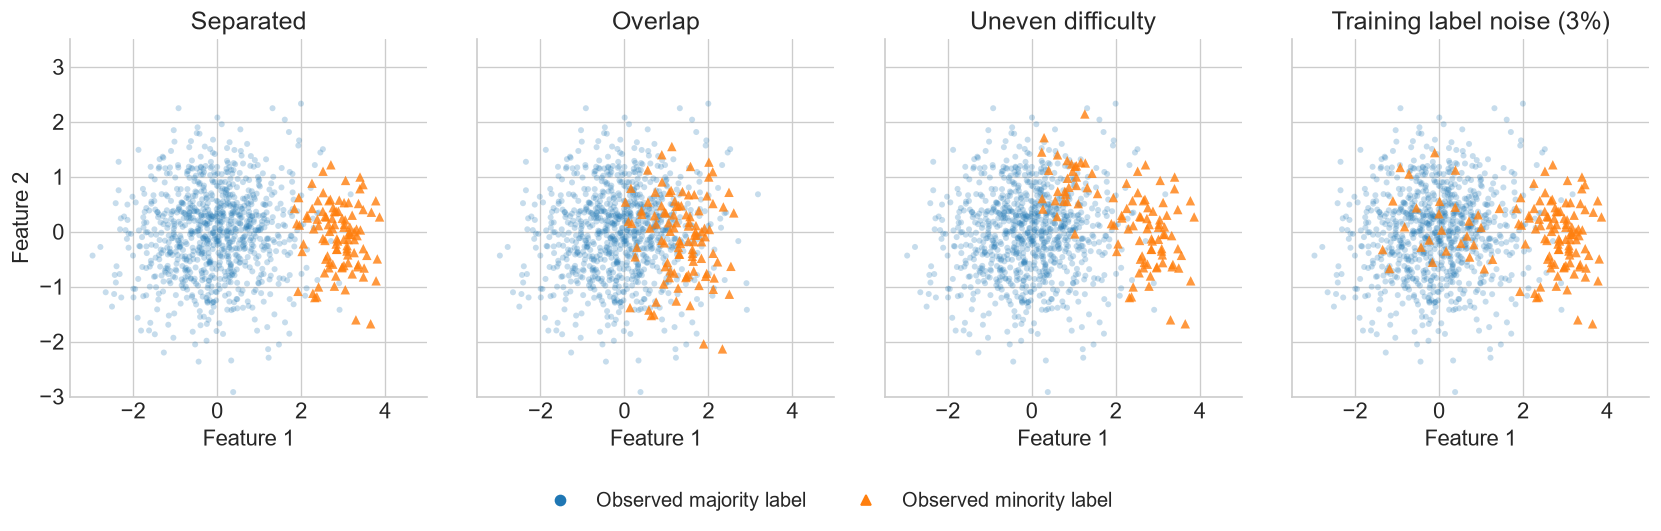

In [ ]:
#| echo: false
#| fig-height: 4.7
#| out-height: "360px"

def sampler_comparison_data(scenario, seed):
    rng = np.random.default_rng(seed)

    def draw(n_majority, n_minority):
        majority = rng.normal([0, 0], [1, .8], size=(n_majority, 2))
        if scenario == 'Overlap':
            minority = rng.normal([1.5, 0], [.7, .7], size=(n_minority, 2))
        else:
            minority = rng.normal([3, 0], [.55, .55], size=(n_minority, 2))
            if scenario == 'Uneven difficulty':
                hard = np.arange(n_minority) < int(.3 * n_minority)
                minority[hard] = rng.normal([.8, 1], [.4, .4], size=(hard.sum(), 2))
        X_draw = np.vstack([majority, minority])
        y_draw = np.r_[np.zeros(n_majority, dtype=int), np.ones(n_minority, dtype=int)]
        order = rng.permutation(len(y_draw))
        return X_draw[order], y_draw[order]

    X_train_draw, y_train_draw = draw(900, 100)
    X_test_draw, y_test_draw = draw(2700, 300)
    if scenario == 'Training label noise':
        rows = rng.choice(len(y_train_draw), size=30, replace=False)
        y_train_draw[rows] = 1 - y_train_draw[rows]
    return X_train_draw, y_train_draw, X_test_draw, y_test_draw

def run_sampler_comparison():

    # Fixed scenarios and seeds; no search for settings that favor a method.
    rows = []
    for scenario in ['Separated', 'Overlap', 'Uneven difficulty', 'Training label noise']:
        for seed in range(42, 52):
            X_train_draw, y_train_draw, X_test_draw, y_test_draw = sampler_comparison_data(scenario, seed)
            samplers = [
                ('No sampling', 'passthrough'),
                ('SMOTE', SMOTE(random_state=seed)),
                ('Borderline-SMOTE', BorderlineSMOTE(random_state=seed)),
                ('ADASYN', ADASYN(random_state=seed)),
            ]
            for method, sampler in samplers:
                model = ImbPipeline([
                    ('scale', StandardScaler()),
                    ('sampler', sampler),
                    ('classifier', KNeighborsClassifier(n_neighbors=7)),
                ])
                model.fit(X_train_draw, y_train_draw)
                predictions = model.predict(X_test_draw)
                rows.append({
                    'scenario': scenario, 'seed': seed, 'method': method,
                    'tp': int(((y_test_draw == 1) & (predictions == 1)).sum()),
                    'fp': int(((y_test_draw == 0) & (predictions == 1)).sum()),
                    'fn': int(((y_test_draw == 1) & (predictions == 0)).sum()),
                    'f1': f1_score(y_test_draw, predictions, zero_division=0),
                    'precision': precision_score(y_test_draw, predictions, zero_division=0),
                    'recall': recall_score(y_test_draw, predictions, zero_division=0),
                })
    return pd.DataFrame(rows)

def plot_sampler_comparison_conditions():

    with plt.rc_context({'font.size': 13, 'axes.titlesize': 15}):
        fig, axes = plt.subplots(1, 4, figsize=(14, 4.8), sharex=True, sharey=True)
        fig.subplots_adjust(left=.05, right=.99, bottom=.24, top=.86, wspace=.14)
        for ax, scenario in zip(axes, ['Separated', 'Overlap', 'Uneven difficulty', 'Training label noise']):
            X_train_draw, y_train_draw, _, _ = sampler_comparison_data(scenario, seed=42)
            for label, marker, color, size in [(0, 'o', BLUE, 13), (1, '^', ORANGE, 32)]:
                points = X_train_draw[y_train_draw == label]
                ax.scatter(*points.T, marker=marker, color=color, s=size,
                           alpha=.25 if label == 0 else .8, edgecolors='none')
            ax.set(title=scenario.replace('Training label noise', 'Training label noise (3%)'),
                   xlabel='Feature 1', xlim=(-3.5, 5), ylim=(-3, 3.5))
            ax.set_box_aspect(1)
        axes[0].set_ylabel('Feature 2')
        fig.legend(handles=[
            Line2D([], [], marker='o', ls='', color=BLUE, label='Observed majority label'),
            Line2D([], [], marker='^', ls='', color=ORANGE, label='Observed minority label'),
        ], loc='lower center', bbox_to_anchor=(.5, .01), ncol=2, fontsize=12)
        plt.show()

sampler_comparison_results = run_sampler_comparison()
plot_sampler_comparison_conditions()


# Compare F1, precision, and minority recall

Mean and standard deviation across 10 independent train/test draws, using seeds 42 through 51.

- Higher recall does not necessarily give higher F1.
- These results use one fixed classifier with no tuning; they do not establish a universal sampler ranking.


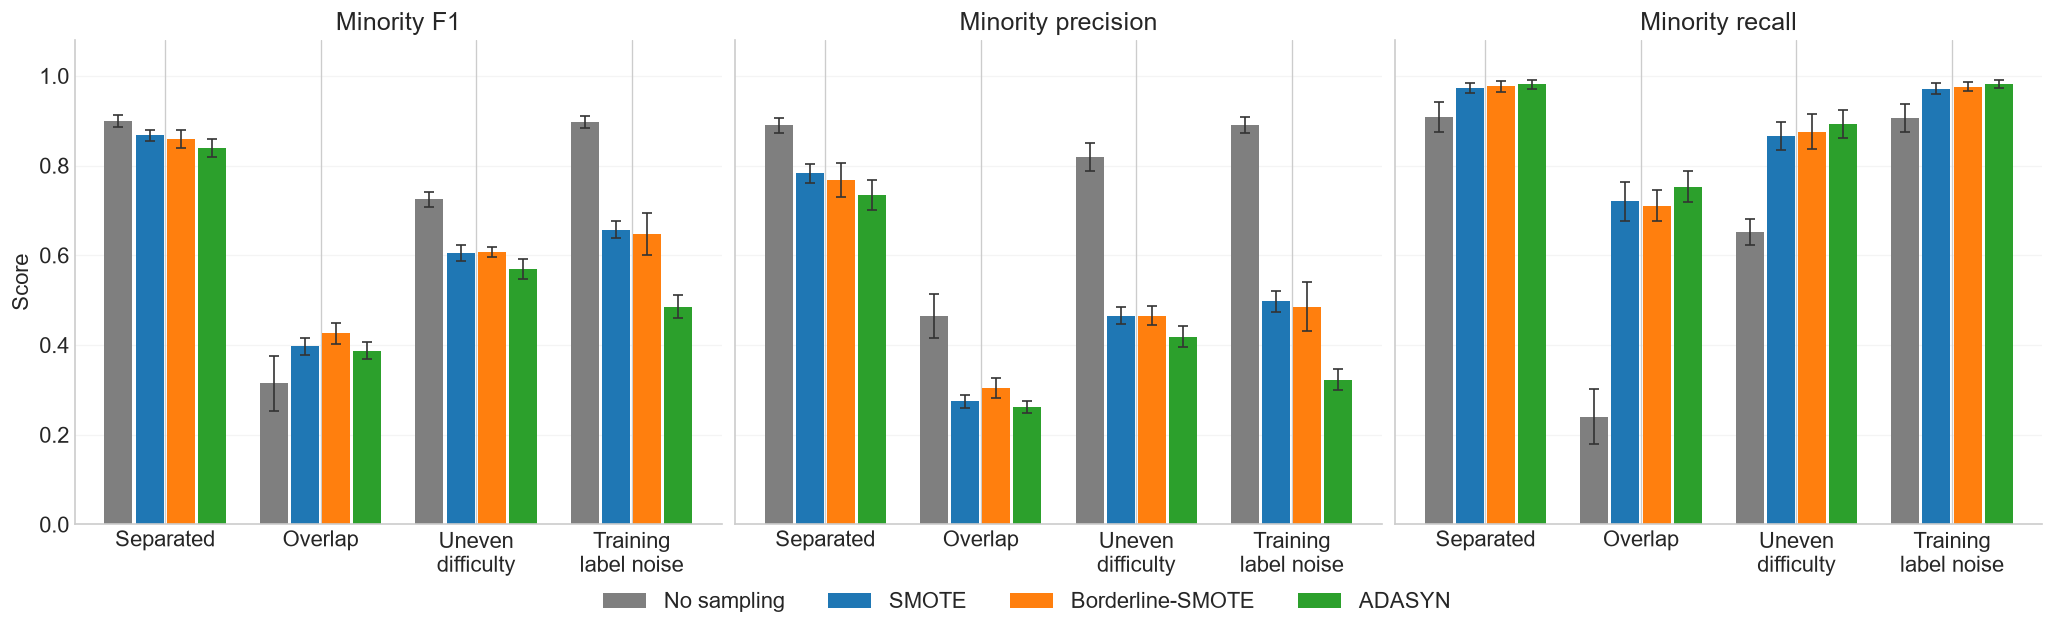

In [ ]:
#| echo: false
#| fig-height: 4.7
#| out-height: "360px"

def plot_sampler_comparison_results(results):

    scenarios = ['Separated', 'Overlap', 'Uneven difficulty', 'Training label noise']
    methods = ['No sampling', 'SMOTE', 'Borderline-SMOTE', 'ADASYN']
    colors = [GRAY, BLUE, ORANGE, GREEN]
    summary = results.groupby(['scenario', 'method'])[['f1', 'precision', 'recall']].agg(['mean', 'std'])
    with plt.rc_context({'font.size': 13, 'axes.titlesize': 15}):
        fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True, layout='constrained')
        for ax, metric, title in zip(axes, ['f1', 'precision', 'recall'], ['Minority F1', 'Minority precision', 'Minority recall']):
            for method_index, (method, color) in enumerate(zip(methods, colors)):
                means = [summary.loc[(scenario, method), (metric, 'mean')] for scenario in scenarios]
                stds = [summary.loc[(scenario, method), (metric, 'std')] for scenario in scenarios]
                positions = np.arange(4) + (method_index - 1.5) * .20
                ax.bar(positions, means, width=.18, yerr=stds, capsize=3, color=color, label=method,
                       error_kw={'ecolor': '#333333', 'elinewidth': 1, 'capthick': 1})
            ax.set(title=title, xticks=range(4),
                   xticklabels=['Separated', 'Overlap', 'Uneven\ndifficulty', 'Training\nlabel noise'],
                   ylim=(0, 1.08), ylabel='Score' if metric == 'f1' else '')
            ax.set_axisbelow(True)
            ax.grid(axis='y', alpha=.2)
        fig.legend(handles=[Patch(facecolor=color, label=method)
                            for method, color in zip(methods, colors)],
                   loc='outside lower center', ncol=4)
        plt.show()

plot_sampler_comparison_results(sampler_comparison_results)


# Why can no augmentation have higher F1?

$$F_1=\frac{2PR}{P+R}=\frac{2TP}{2TP+FP+FN}.$$

- Resampling adds rows, but it does not guarantee more information or a better decision boundary.
- Oversampling can recover more positives while also predicting more false positives.
- If precision falls enough, higher recall can still give lower F1.
- With noisy training labels, samplers can generate more rows around incorrectly labeled points.

# Trace the F1 difference through errors in "Training label noise" (seed 42)


In [ ]:
#| echo: false

noise_comparison_table = (
    sampler_comparison_results.loc[
        (sampler_comparison_results['scenario'] == 'Training label noise')
        & (sampler_comparison_results['seed'] == 42)
    ]
    .set_index('method')[['tp', 'fp', 'fn', 'precision', 'recall', 'f1']]
    .rename(columns={'tp': 'TP', 'fp': 'FP', 'fn': 'FN', 'precision': 'Precision', 'recall': 'Recall', 'f1': 'F1'})
    .round(3)
)
noise_comparison_table


,TP,FP,FN,Precision,Recall,F1
method,,,,,,
No sampling,281,35,19,0.889,0.937,0.912
SMOTE,294,299,6,0.496,0.980,0.658
Borderline-SMOTE,295,271,5,0.521,0.983,0.681
ADASYN,296,736,4,0.287,0.987,0.444


- **Separated classes:** the untreated baseline has the highest mean F1.
- **Overlap:** Borderline-SMOTE has the highest mean F1 in this experiment.
- **Uneven difficulty:** ADASYN recovers more positives, but the untreated baseline has higher mean F1.
- **Training label noise:** ADASYN has the highest recall and the lowest mean F1.
    - Concentrating on difficult points can reinforce incorrect labels.




# Pipelines with resampling need imblearn

```bash
pip install imbalanced-learn
```

`sklearn.pipeline.Pipeline` is designed for transformers and estimators.

- `estimator = obj.fit(data, targets)`

`imblearn.pipeline.Pipeline` is designed for transformers, resamplers, and estimators.

- Resampling is part of training, so it must happen inside the pipeline and inside each cross-validation fold.
- To resample a data sets, each sampler implements a `fit_resample` method:
    - `data_resampled, targets_resampled = obj.fit_resample(data, targets)`

```python
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
pipeline = ImbPipeline([
    ("preprocessing", preprocessor),
    ("sampler", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(max_iter=2000)),
])
```




# Create a deliberately imbalanced dataset

We will use a synthetic binary classification dataset: `y=1` is a rare high-risk event, such as fraud, churn, default, or failure.


In [ ]:
#| echo: false
# Build a controlled rare-event problem with about 6% positive examples.
X_array, y_array = make_classification(
    n_samples=5000,
    n_features=12,
    n_informative=5,
    n_redundant=3,
    n_clusters_per_class=2,
    weights=[0.94, 0.06],
    class_sep=0.9,
    flip_y=0.02,
    random_state=RANDOM_STATE,
)

feature_names = [f"feature_{i:02d}" for i in range(X_array.shape[1])]
X = pd.DataFrame(X_array, columns=feature_names)
y = pd.Series(y_array, name="high_risk")

class_counts = y.value_counts().sort_index()
class_rates = y.value_counts(normalize=True).sort_index()

pd.DataFrame({"count": class_counts, "rate": class_rates.round(3)})


,count,rate
high_risk,,
0,4658,0.932
1,342,0.068


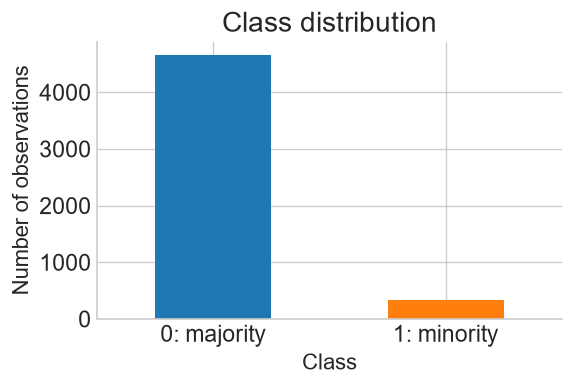

In [ ]:
#| echo: false
# Visualize the base rate before discussing any model metrics.
fig, ax = plt.subplots(figsize=(5, 3))
class_counts.plot(kind="bar", ax=ax, color=[BLUE, ORANGE])
ax.set_title("Class distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of observations")
ax.set_xticklabels(["0: majority", "1: minority"], rotation=0)
plt.show()


# Visual intuition

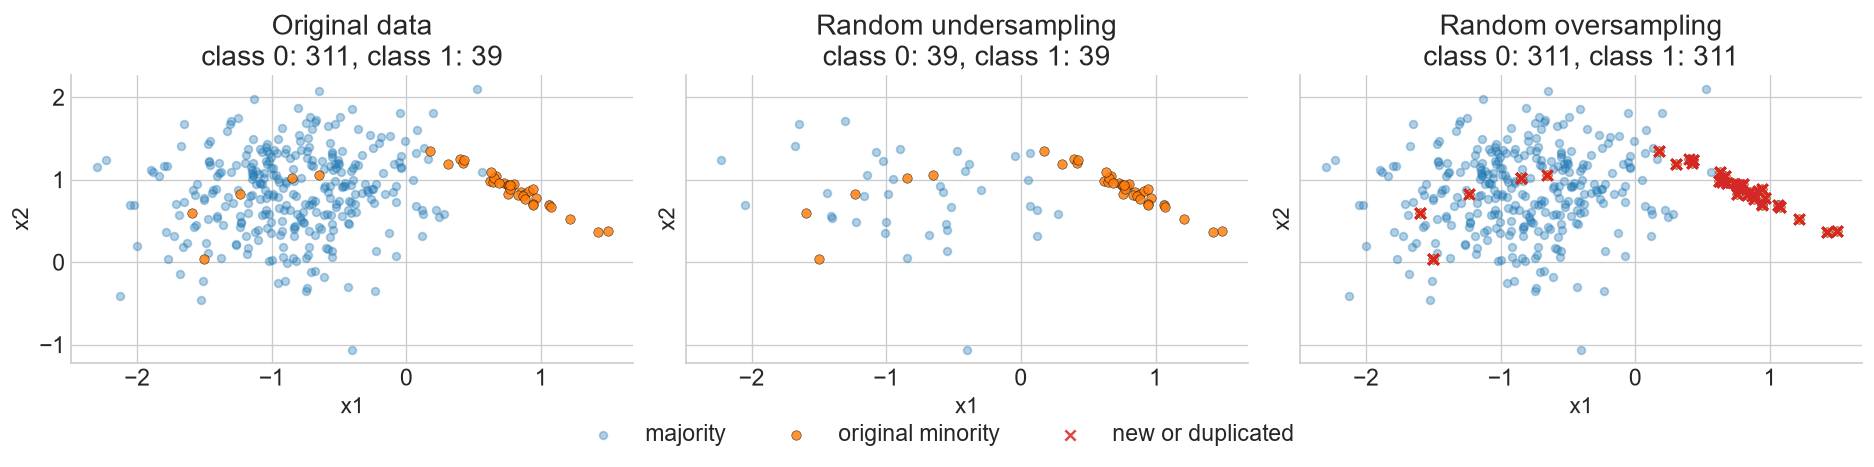

In [ ]:
#| echo: false

# Create a small two-feature dataset so synthetic samples can be plotted directly.
X_2d_array, y_2d_array = make_classification(
    n_samples=350,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.9, 0.1],
    class_sep=0.85,
    flip_y=0.03,
    random_state=RANDOM_STATE,
)

X_2d = pd.DataFrame(X_2d_array, columns=["x1", "x2"])
y_2d = pd.Series(y_2d_array, name="minority_class")

pd.DataFrame({"count": y_2d.value_counts().sort_index()})

# Apply each sampler to the same toy data and plot the resulting training geometry.
toy_samplers = {
    "Original data": None,
    "Random undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "Random oversampling": RandomOverSampler(random_state=RANDOM_STATE),
}
toy_samplers2 = {
    "SMOTE": SMOTE(random_state=RANDOM_STATE, k_neighbors=5),
    "Borderline-SMOTE": BorderlineSMOTE(random_state=RANDOM_STATE, k_neighbors=5),
    "ADASYN": ADASYN(random_state=RANDOM_STATE, n_neighbors=5),
}
def apply_sampler_for_plot(sampler, X, y):
    if sampler is None:
        X_resampled = X.copy()
        y_resampled = y.copy()
    else:
        X_values, y_values = sampler.fit_resample(X, y)
        X_resampled = pd.DataFrame(X_values, columns=X.columns)
        y_resampled = pd.Series(y_values, name=y.name)

    original_mask = np.arange(len(X_resampled)) < len(X)
    return X_resampled, y_resampled, original_mask

def plot_resampled_dataset(ax, title, X_resampled, y_resampled, original_mask):
    majority = y_resampled == 0
    minority = y_resampled == 1
    synthetic = ~original_mask

    ax.scatter(
        X_resampled.loc[majority, "x1"],
        X_resampled.loc[majority, "x2"],
        s=22,
        alpha=0.35,
        label="majority",
        color=BLUE,
    )
    ax.scatter(
        X_resampled.loc[minority & original_mask, "x1"],
        X_resampled.loc[minority & original_mask, "x2"],
        s=32,
        alpha=0.85,
        label="original minority",
        color=ORANGE,
        edgecolor="black",
        linewidth=0.3,
    )
    ax.scatter(
        X_resampled.loc[synthetic, "x1"],
        X_resampled.loc[synthetic, "x2"],
        s=38,
        alpha=0.85,
        label="new or duplicated",
        color=RED,
        marker="x",
    )

    counts = y_resampled.value_counts().sort_index()
    ax.set_title(f"{title}\nclass 0: {counts.get(0, 0)}, class 1: {counts.get(1, 0)}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

def plot_toy_samplers(samplers):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
    for ax, (name, sampler) in zip(axes.ravel(), samplers.items()):
        X_resampled, y_resampled, original_mask = apply_sampler_for_plot(sampler, X_2d, y_2d)
        plot_resampled_dataset(ax, name, X_resampled, y_resampled, original_mask)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3)
    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.show()

plot_toy_samplers(toy_samplers)


- Random *under sampling* decreases the majority count by sampling existing observations.
- Random *oversampling* increases the minority count by repeating existing observations, so the red crosses sit directly on top of known points.

# Visual intuition

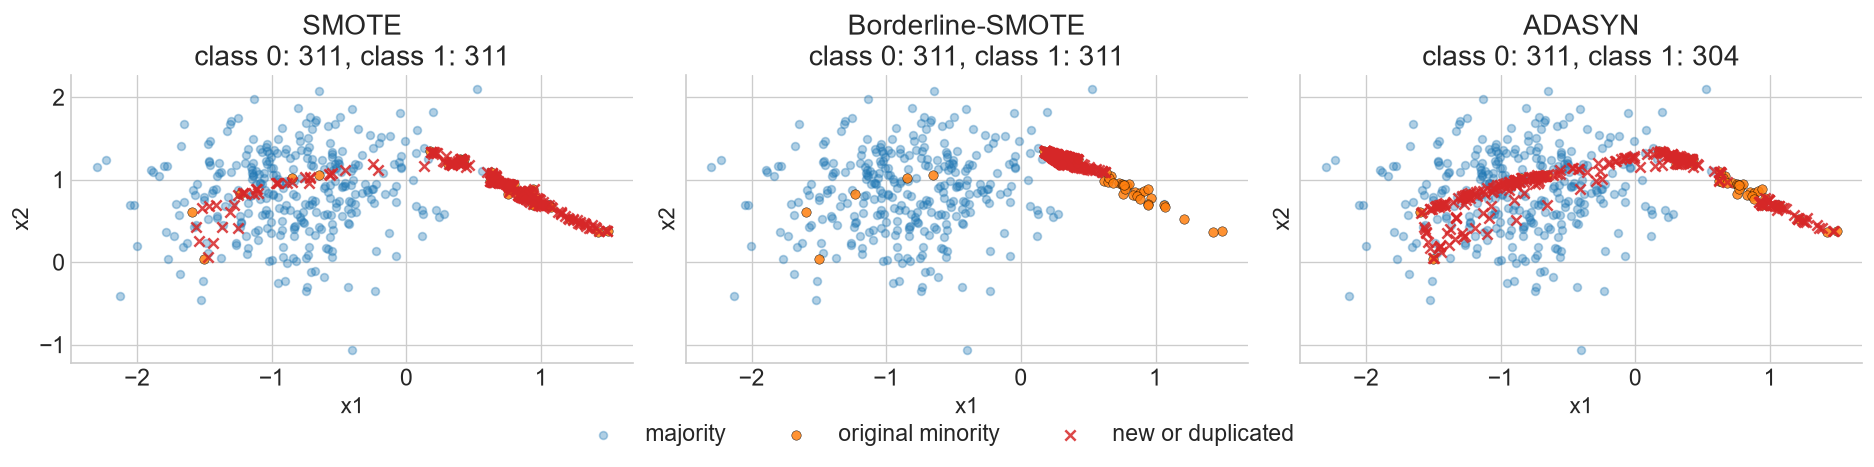

In [ ]:
#| echo: false

plot_toy_samplers(toy_samplers2)


- *SMOTE* fills segments between nearby minority points.
    - This smooths sparse minority regions, but assumes that interpolation produces valid records.
- *Borderline-SMOTE* tries to synthesize near the frontier between classes.
    - It is useful when boundary recall matters, but it can be sensitive to overlap and label noise.
- *ADASYN* places more synthetic examples in locally difficult regions.
    - Compared with SMOTE, it often concentrates more strongly near areas where the majority class surrounds the minority class.

# Baseline pipeline

In [ ]:
preprocessor = StandardScaler()
baseline_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)
baseline_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_mod

# Candidate pipelines

We compare seven strategies:

1. No imbalance treatment (baseline pipeline).
2. `class_weight="balanced"`.
3. Random undersampling.
4. Random oversampling.
5. SMOTE.
6. ADASYN.
7. Borderline-SMOTE.

```python
pipelines = {
    "No treatment": Pipeline(
        [("preprocessing", preprocessor), ("classifier", logistic_regression())]
    ),
    "Class weight": Pipeline(
        [("preprocessing", preprocessor), ("classifier", logistic_regression(class_weight="balanced"))]
    ),
    "Random undersampling": ImbPipeline(
        [("preprocessing", preprocessor), ("sampler", RandomUnderSampler(random_state=RANDOM_STATE)), ("classifier", logistic_regression())]
    ), # ...
}
```


In [ ]:
#| echo: false
#| output: false
# Compare ordinary sklearn pipelines with imblearn pipelines that can contain samplers.
def logistic_regression(class_weight=None):
    return LogisticRegression(
        max_iter=2000,
        class_weight=class_weight,
        random_state=RANDOM_STATE,
    )

samplers = {
    "Random undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "Random oversampling": RandomOverSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE, k_neighbors=5),
    "ADASYN": ADASYN(random_state=RANDOM_STATE, n_neighbors=5),
    "Borderline-SMOTE": BorderlineSMOTE(random_state=RANDOM_STATE, k_neighbors=5),
}
pipelines = {
    "No treatment": Pipeline([("preprocessing", preprocessor), ("classifier", logistic_regression())]),
    "Class weight": Pipeline([
        ("preprocessing", preprocessor), ("classifier", logistic_regression(class_weight="balanced")),
    ]),
}
pipelines.update({
    name: ImbPipeline([
        ("preprocessing", preprocessor), ("sampler", sampler), ("classifier", logistic_regression()),
    ])
    for name, sampler in samplers.items()
})
list(pipelines)


['No treatment', 'Class weight', 'Random undersampling', 'Random oversampling', 'SMOTE', 'ADASYN', 'Borderline-SMOTE']

In [ ]:
#| echo: false
#| output: false
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn / (tn + fp) if (tn + fp) else np.nan

def evaluate_pipeline(name, pipeline, X, y, cv, threshold=0.5):
    fold_rows = []
    out_of_fold_scores = pd.Series(index=y.index, dtype=float)

    for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y), start=1):
        model = clone(pipeline)
        X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
        y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

        model.fit(X_train, y_train)
        y_score = model.predict_proba(X_valid)[:, 1]
        y_pred = (y_score >= threshold).astype(int)
        out_of_fold_scores.iloc[valid_idx] = y_score

        fold_rows.append(
            {
                "method": name,
                "fold": fold,
                "accuracy": accuracy_score(y_valid, y_pred),
                "precision": precision_score(y_valid, y_pred, zero_division=0),
                "recall": recall_score(y_valid, y_pred, zero_division=0),
                "specificity": specificity_score(y_valid, y_pred),
                "f1": f1_score(y_valid, y_pred, zero_division=0),
            }
        )

    return pd.DataFrame(fold_rows), out_of_fold_scores

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_results = []
oof_scores = {}

for name, pipeline in pipelines.items():
    fold_df, scores = evaluate_pipeline(name, pipeline, X, y, cv)
    fold_results.append(fold_df)
    oof_scores[name] = scores

fold_results = pd.concat(fold_results, ignore_index=True)
fold_results.pivot(index="fold", columns="method", values="f1").round(3)


method,ADASYN,Borderline-SMOTE,Class weight,No treatment,Random oversampling,Random undersampling,SMOTE
fold,,,,,,,
1,0.258,0.287,0.247,0.080,0.245,0.257,0.253
2,0.272,0.296,0.259,0.135,0.259,0.249,0.268
3,0.285,0.295,0.280,0.028,0.281,0.275,0.285
4,0.278,0.307,0.285,0.107,0.280,0.266,0.290
5,0.305,0.330,0.302,0.104,0.303,0.292,0.308


# Comparison table

The table reports mean cross-validation performance and fold-to-fold variability.

> - **Precision**: among predicted positives, how many were actually positive?
> - **Recall** or sensitivity: among actual positives, how many did we find?
> - **Specificity**: among actual negatives, how many did we correctly reject?
> - **F1 score**: harmonic mean of precision and recall.


In [ ]:
#| echo: false
# Average fold-level metrics to compare strategies at the default 0.5 threshold.
summary = (
    fold_results.groupby("method")
    .agg(
        Accuracy=("accuracy", "mean"),
        Precision=("precision", "mean"),
        Recall=("recall", "mean"),
        Specificity=("specificity", "mean"),
        F1=("f1", "mean"),
        F1_std=("f1", "std"),
    )
    .sort_values("F1", ascending=False)
)

summary.round(3)


,Accuracy,Precision,Recall,Specificity,F1,F1_std
method,,,,,,
Borderline-SMOTE,0.773,0.192,0.719,0.777,0.303,0.017
SMOTE,0.734,0.172,0.754,0.733,0.281,0.021
ADASYN,0.732,0.172,0.757,0.730,0.279,0.017
Class weight,0.725,0.168,0.757,0.723,0.275,0.022
Random oversampling,0.726,0.167,0.751,0.724,0.274,0.022
Random undersampling,0.714,0.163,0.760,0.711,0.268,0.017
No treatment,0.932,0.552,0.050,0.997,0.091,0.040


# Confusion matrices

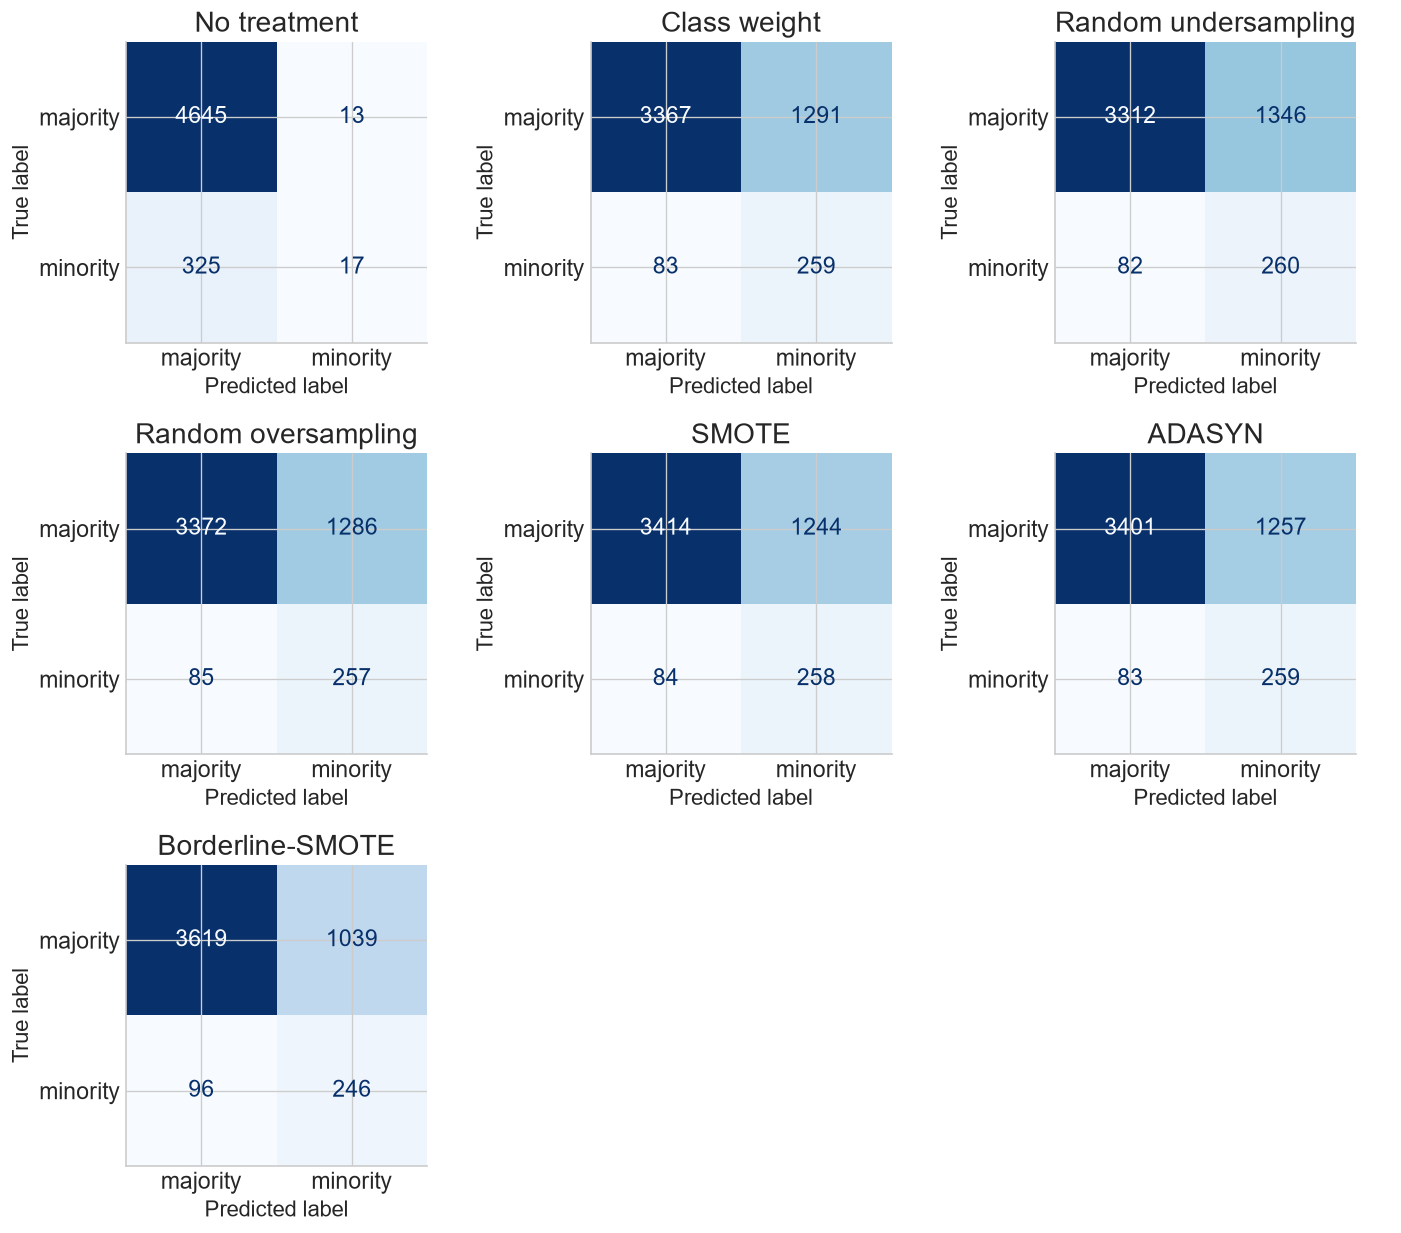

In [ ]:
#| echo: false
# Convert out-of-fold probabilities into labels before drawing confusion matrices.
n_methods = len(oof_scores)
n_cols = 3
n_rows = int(np.ceil(n_methods / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.5 * n_rows))
axes = np.asarray(axes).ravel()

for ax in axes[n_methods:]:
    ax.axis("off")

for ax, (name, scores) in zip(axes, oof_scores.items()):
    y_pred = (scores >= 0.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y,
        y_pred,
        labels=[0, 1],
        display_labels=["majority", "minority"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


# From scores to decisions

:::: {.columns}
::: {.column width="80%"}

Precision ($\frac{TP}{TP + FP}$; high $\rightarrow$ few false alarms) and Recall ($\frac{TP}{TP + FN}$; high recall $\rightarrow$ few missed positives).

- *High recall but low precision*: return many positive results, but most of its predicted labels are incorrect.
- *High precision but low recall*: return few positive results, but most of its predicted labels are correct.

A model produces a positive-class probability $p$ and predicts positive when $p \ge thr$.

- The threshold $thr$ decides which scores become positive predictions


:::
::: {.column width="20%"}

![](img/PrecisionrecallDogExample.svg.png)

:::
::::

# Threshold adjustment


The right threshold depends on the operational cost of each error type. **Lowering $thr$ changes the confusion matrix**.

- `predict` usually applies a threshold of `0.5`. In a high-cost FN scenario, such as medical screening, we may prefer a lower threshold.


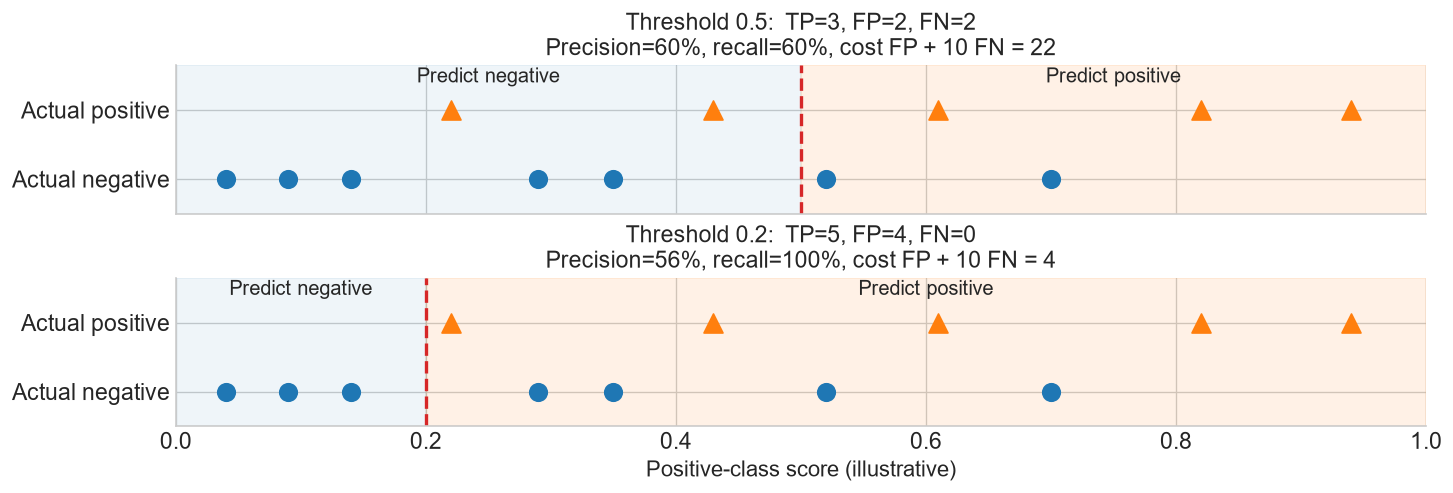

In [ ]:
#| echo: false
#| fig-height: 4.7
# Synthetic data illustrate the mechanism, not model performance.
def plot_thresholds():
    # A fixed illustrative score ranking, not calibrated model probabilities.
    scores = np.array([.04, .09, .14, .22, .29, .35, .43, .52, .61, .70, .82, .94])
    y = np.array([0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1])
    fig, axes = plt.subplots(2, 1, figsize=(12, 4), sharex=True, layout="constrained")
    for ax, threshold in zip(axes, [.5, .2]):
        pred = scores >= threshold
        tp, fp = np.sum(pred & (y == 1)), np.sum(pred & (y == 0))
        fn = np.sum(~pred & (y == 1))
        ax.axvspan(0, threshold, color=BLUE, alpha=.07)
        ax.axvspan(threshold, 1, color=ORANGE, alpha=.10)
        ax.scatter(scores[y == 0], np.zeros(sum(y == 0)), s=110, c=BLUE, zorder=3)
        ax.scatter(scores[y == 1], np.ones(sum(y == 1)), s=130, c=ORANGE, marker="^", zorder=3)
        ax.axvline(threshold, c=RED, ls="--", lw=2)
        ax.set(yticks=[0, 1], yticklabels=["Actual negative", "Actual positive"],
               ylim=(-.5, 1.65), xlim=(0, 1))
        ax.text(threshold/2, 1.4, "Predict negative", ha="center", fontsize=12)
        ax.text((threshold+1)/2, 1.4, "Predict positive", ha="center", fontsize=12)
        ax.set_title(f"Threshold {threshold:.1f}:  TP={tp}, FP={fp}, FN={fn}\n"
                     f"Precision={tp/(tp+fp):.0%}, recall={tp/(tp+fn):.0%}, cost FP + 10 FN = {fp+10*fn}",
                     fontsize=14)
    axes[-1].set_xlabel("Positive-class score (illustrative)")
    plt.show()

plot_thresholds()


**Precision**

- If $thr$ was too high, the new results may all be TP, which will increase precision.
- If $thr$ was about right or low, further lowering it will introduce FP, decreasing precision.

**Recall**: lowering $thr$ labels more cases as positive, this can turn some FN into TP, increasing recall.

In [ ]:
#| echo: false
#| output: false
# Recompute metrics over a grid of decision thresholds for one selected method.

# Select the highest mean cross-validation F1 at the default 0.5 threshold.
selected_method = summary["F1"].idxmax()
threshold_grid = np.linspace(0.00, 1.00, 8)
def metrics_at_thresholds(y_true, y_score, thresholds):
    rows = []
    for threshold in thresholds:
        y_pred = (y_score >= threshold).astype(int)
        rows.append(
            {
                "threshold": threshold,
                "precision": precision_score(y_true, y_pred, zero_division=0),
                "recall": recall_score(y_true, y_pred, zero_division=0),
                "specificity": specificity_score(y_true, y_pred),
                "f1": f1_score(y_true, y_pred, zero_division=0),
            }
        )
    return pd.DataFrame(rows)

# Use one shared method and threshold grid for the threshold plot and precision-recall curve.
threshold_results = metrics_at_thresholds(y, oof_scores[selected_method], threshold_grid)
threshold_results.round(3)


,threshold,precision,recall,specificity,f1
0,0.000,0.068,1.000,0.000,0.128
1,0.143,0.095,0.927,0.354,0.173
2,0.286,0.123,0.848,0.558,0.216
3,0.429,0.163,0.766,0.710,0.268
4,0.571,0.219,0.643,0.831,0.326
5,0.714,0.276,0.447,0.914,0.342
6,0.857,0.345,0.234,0.967,0.279
7,1.000,0.000,0.000,1.000,0.000


# Threshold adjustment

Increasing $thr$ asks for more confidence before predicting the positive class, so recall tends to fall and precision may rise.

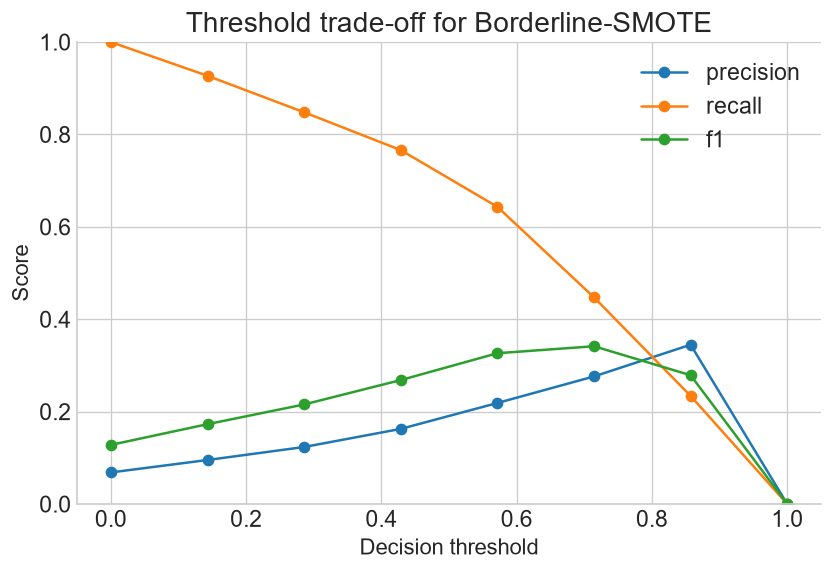

In [ ]:
#| echo: false
# Plot the metric trade-off created by moving the classification threshold.
fig, ax = plt.subplots(figsize=(8, 5))
for metric in ["precision", "recall", "f1"]:
    ax.plot(threshold_results["threshold"], threshold_results[metric], marker="o", label=metric)
ax.set(title=f"Threshold trade-off for {selected_method}",
       xlabel="Decision threshold", ylabel="Score", ylim=(0, 1))
ax.legend()
plt.show()


# Precision-recall curves

A precision-recall curve shows every precision/recall pair produced as we *vary the classification threshold* for binary classification.

- *Lower $thr$* predict more positives: *recall usually rises* and *precision often falls*.
- *Higher $thr$* predict fewer positives: *precision may rise* and *recall often falls*.
- Curves closer to the upper-right corner are better because they keep high precision while recovering many positives.

Average precision ($AP=\sum_n (R_n - R_{n-1}) P_n$) summarizes the curve as the weighted mean of precisions achieved at each threshold.

- $P_n$ and $R_n$ are the precision and recall at the nth threshold.
- The horizontal baseline is the positive-class rate: a model below this line is worse than ranking cases at random.

<div></div>

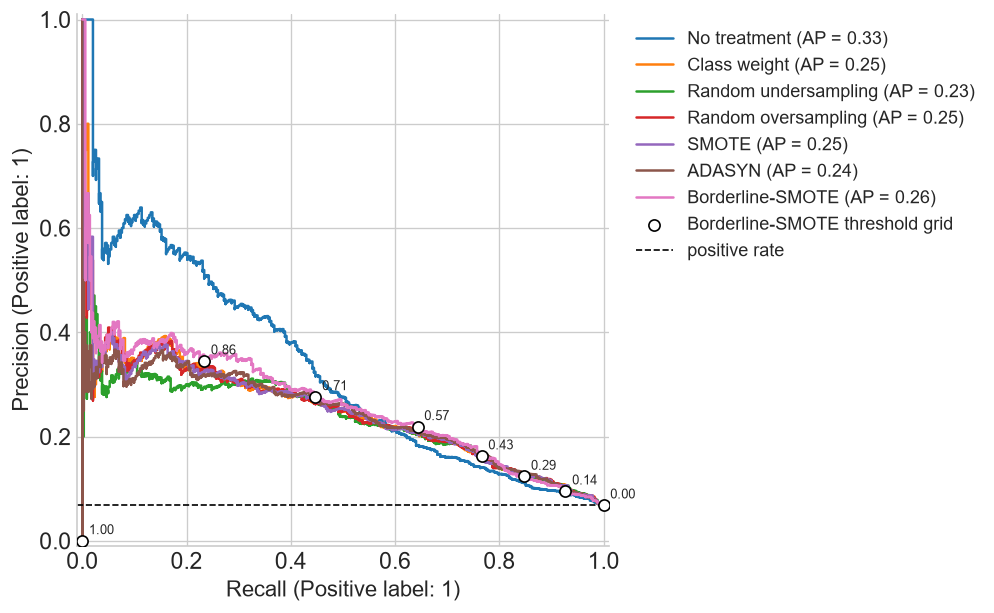

In [ ]:
#| echo: false
# Plot precision-recall curves from validation-only scores for each method.

fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")

for name, scores in oof_scores.items():
    PrecisionRecallDisplay.from_predictions(y, scores, name=name, ax=ax)

# Highlight thresholds for the best method from the comparison table.
selected_scores = oof_scores[selected_method]
threshold_points = threshold_results[["threshold", "precision", "recall"]].copy()
ax.scatter(
    threshold_points["recall"],
    threshold_points["precision"],
    color="white",
    edgecolor="black",
    linewidth=1,
    s=45,
    zorder=5,
    label=f"{selected_method} threshold grid",
)
for _, row in threshold_points.iterrows():
    ax.annotate(
        f"{row['threshold']:.2f}",
        (row["recall"], row["precision"]),
        textcoords="offset points",
        xytext=(4, 4),
        fontsize=8,
    )

positive_rate = y.mean()
ax.axhline(positive_rate, color="black", linestyle="--", linewidth=1, label="positive rate")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=11)
plt.show()


# Choose a threshold for high-cost false negatives

Suppose a false negative costs 10 times as much as a false positive.

- A false positive creates an unnecessary follow-up, while a false negative misses a truly high-risk case.
- With this cost ratio, the best threshold may accept more false positives if doing so prevents enough false negatives.

For the selected method and each threshold, we compute the confusion matrix and then calculate:

- $total\ cost = FP \times cost(FP) + FN \times cost(FN)$

With $cost(FP)=1$ and $cost(FN)=10$, this becomes:

- $total\ cost = FP + 10 \times FN$
- If a threshold produces 961 false positives and 101 false negatives, then: $total\ cost = 961 + 10 \times 101 = 1971$


In [ ]:
#| echo: false
# Search thresholds with a simple cost function where false negatives are expensive.
def cost_at_threshold(y_true, y_score, threshold, false_positive_cost=1, false_negative_cost=10):
    y_pred = (y_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    total_cost = fp * false_positive_cost + fn * false_negative_cost
    return {
        "threshold": threshold,
        "false_positives": fp,
        "false_negatives": fn,
        "total_cost": total_cost,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }

# Tune the same comparison-table winner used in the threshold plots.
cost_rows = []
for threshold in np.linspace(0.05, 0.95, 91):
    row = cost_at_threshold(y, oof_scores[selected_method], threshold)
    row["method"] = selected_method
    cost_rows.append(row)

cost_results = pd.DataFrame(cost_rows)
best_threshold = cost_results.loc[[cost_results["total_cost"].idxmin()]]
best_threshold.round(3)


,threshold,false_positives,false_negatives,total_cost,precision,recall,f1,method
47,0.52,961,101,1971,0.2,0.705,0.312,Borderline-SMOTE


# Leakage warning

Resampling *is part of model training*: it must be learned from the training data only.

- Do **not** apply SMOTE or oversampling before splitting the data. *Why*?

:::{.fragment}
- If synthetic points are created before a train/test split, information from validation/test observations can leak into the training set.
- The same rule applies to cross-validation: resampling must happen **inside each training fold**, not once globally before cross-validation.
- This is why we use `imblearn.pipeline.Pipeline` whenever the pipeline contains a sampler.
:::

# How information leaks through a synthetic row

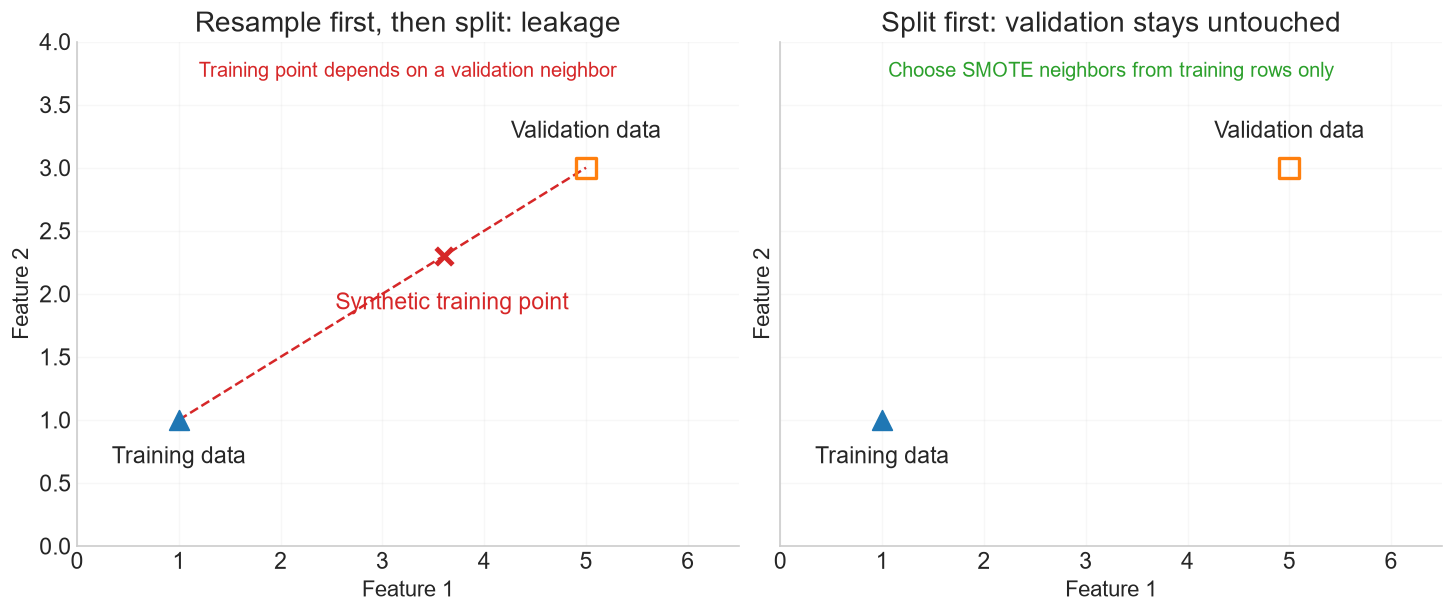

In [ ]:
#| echo: false
#| fig-height: 4.7
# Synthetic data illustrate the mechanism, not model performance.
def plot_leakage():
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True, layout="constrained")
    a, b = np.array([1., 1.]), np.array([5., 3.])
    synthetic = a + .65 * (b-a)
    for ax in axes:
        ax.scatter(*a, s=140, c=BLUE, marker="^", zorder=3)
        ax.scatter(*b, s=140, facecolors="none", edgecolors=ORANGE, linewidth=2, marker="s", zorder=3)
        ax.annotate("Training data", a, xytext=(0, -26), textcoords="offset points", ha="center")
        ax.annotate("Validation data", b, xytext=(0, 18), textcoords="offset points", ha="center")
        ax.set(xlim=(0, 6.5), ylim=(0, 4), xlabel="Feature 1", ylabel="Feature 2")
        ax.grid(alpha=.15)
    axes[0].plot(*np.array([a,b]).T, "--", color=RED)
    axes[0].scatter(*synthetic, s=100, c=RED, marker="x", linewidth=3)
    axes[0].annotate("Synthetic training point", synthetic, xytext=(5, -32), textcoords="offset points", ha="center", color=RED)
    axes[0].set_title("Resample first, then split: leakage")
    axes[1].set_title("Split first: validation stays untouched")
    axes[0].text(.5, .96, "Training point depends on a validation neighbor", transform=axes[0].transAxes,
                 ha="center", va="top", color=RED, fontsize=12)
    axes[1].text(.5, .96, "Choose SMOTE neighbors from training rows only", transform=axes[1].transAxes,
                 ha="center", va="top", color=GREEN, fontsize=12)
    plt.show()

plot_leakage()


# Leakage can hide a missing minority region

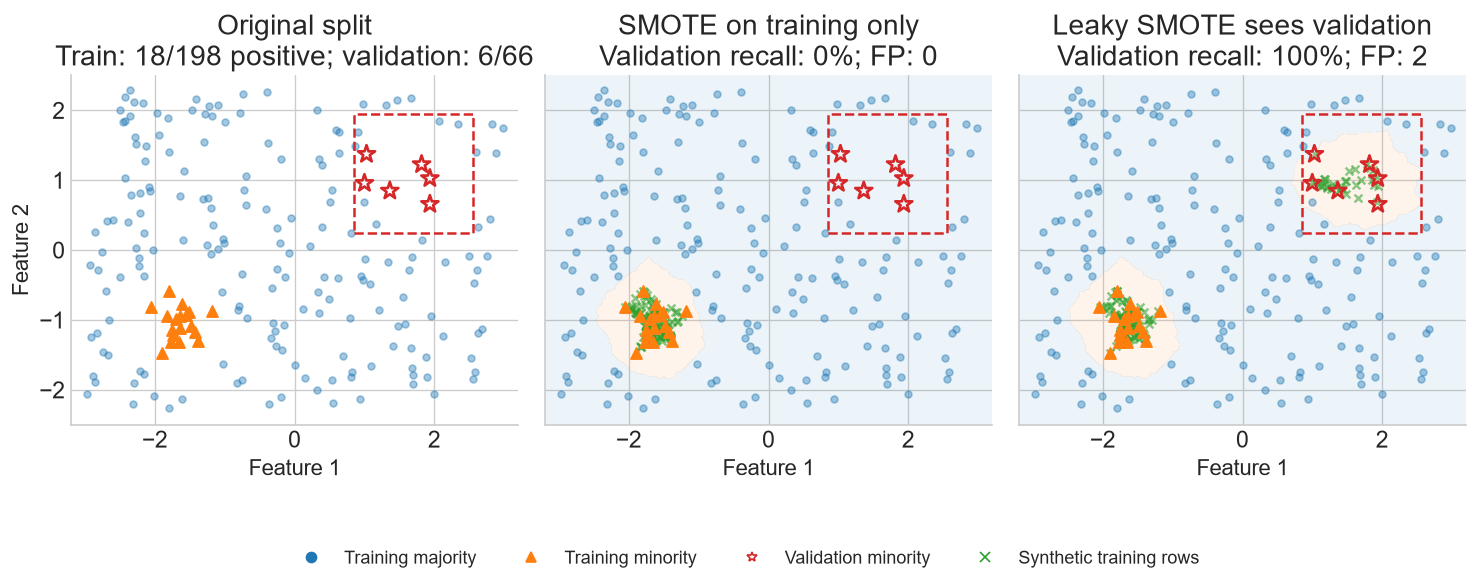

In [ ]:
#| echo: false
#| fig-height: 4.8

def plot_validation_region_leakage():

    rng = np.random.default_rng(42)
    train_center = np.array([-1.7, -1.1])
    valid_center = np.array([1.7, 1.1])
    # Deliberately hold out one entire minority region: a region-shift stress test.
    # Both sets still have the same class ratio, so stratification cannot fix this.
    def majority_points(n):
        candidates = rng.uniform([-3, -2.3], [3, 2.3], size=(4*n, 2))
        outside = ((np.linalg.norm(candidates-train_center, axis=1) > .8)
                   & (np.linalg.norm(candidates-valid_center, axis=1) > .8))
        return candidates[outside][:n]

    X_train_demo = np.vstack([majority_points(180), rng.normal(train_center, .23, size=(18, 2))])
    y_train_demo = np.r_[np.zeros(180, dtype=int), np.ones(18, dtype=int)]
    X_valid_demo = np.vstack([majority_points(60), rng.normal(valid_center, .23, size=(6, 2))])
    y_valid_demo = np.r_[np.zeros(60, dtype=int), np.ones(6, dtype=int)]
    assert np.isclose(y_train_demo.mean(), y_valid_demo.mean())

    X_safe, y_safe = SMOTE(random_state=42).fit_resample(X_train_demo, y_train_demo)
    # Intentionally wrong: validation rows influence SMOTE's neighbor graph.
    X_all = np.vstack([X_train_demo, X_valid_demo])
    y_all = np.r_[y_train_demo, y_valid_demo]
    X_global, y_global = SMOTE(random_state=42).fit_resample(X_all, y_all)
    generated = X_global[len(X_all):]
    # Equalize synthetic counts to isolate the source of neighbor information.
    n_new = len(X_safe) - len(X_train_demo)
    leaked_new = generated[rng.permutation(len(generated))[:n_new]]
    X_leaked = np.vstack([X_train_demo, leaked_new])
    y_leaked = np.r_[y_train_demo, np.ones(n_new, dtype=int)]
    assert np.array_equal(np.bincount(y_safe), np.bincount(y_leaked))

    xx, yy = np.meshgrid(np.linspace(-3.2, 3.2, 240), np.linspace(-2.5, 2.5, 180))
    grid = np.c_[xx.ravel(), yy.ravel()]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.8), sharex=True, sharey=True)
    fig.subplots_adjust(top=.80, bottom=.20, wspace=.06)
    examples = [('Original split', None, None),
                ('SMOTE on training only', X_safe, y_safe),
                ('Leaky SMOTE sees validation', X_leaked, y_leaked)]
    for ax, (title, X_fit, y_fit) in zip(axes, examples):
        if X_fit is not None:
            model = KNeighborsClassifier(n_neighbors=5).fit(X_fit, y_fit)
            labels = model.predict(grid).reshape(xx.shape)
            ax.contourf(xx, yy, labels, levels=[-.5, .5, 1.5], colors=[BLUE, ORANGE], alpha=.08)
            synthetic = X_fit[len(X_train_demo):]
            ax.scatter(*synthetic.T, marker='x', color=GREEN, s=22, alpha=.55)
            predictions = model.predict(X_valid_demo)
            recall = recall_score(y_valid_demo, predictions)
            false_positives = int(np.sum((predictions == 1) & (y_valid_demo == 0)))
            title += f'\nValidation recall: {recall:.0%}; FP: {false_positives}'
        else:
            title += '\nTrain: 18/198 positive; validation: 6/66'
        ax.scatter(*X_train_demo[y_train_demo == 0].T, s=17, color=BLUE, alpha=.4)
        ax.scatter(*X_train_demo[y_train_demo == 1].T, s=45, marker='^', color=ORANGE, zorder=4)
        ax.scatter(*X_valid_demo[y_valid_demo == 1].T, s=115, marker='*',
                   facecolors='none', edgecolors=RED, linewidth=1.6, zorder=5)
        ax.add_patch(Rectangle((.85, .25), 1.7, 1.7, fill=False, edgecolor=RED, linestyle='--', linewidth=1.5))
        ax.set(title=title, xlabel='Feature 1', xlim=(-3.2, 3.2), ylim=(-2.5, 2.5))
        ax.set_aspect('equal')
    axes[0].set_ylabel('Feature 2')
    fig.legend(handles=[
        Line2D([], [], marker='o', ls='', color=BLUE, label='Training majority'),
        Line2D([], [], marker='^', ls='', color=ORANGE, label='Training minority'),
        Line2D([], [], marker='*', ls='', markerfacecolor='none', color=RED, label='Validation minority'),
        Line2D([], [], marker='x', ls='', color=GREEN, label='Synthetic training rows'),
    ], loc='lower center', bbox_to_anchor=(.5, .02), ncol=4, fontsize=11)
    plt.show()

plot_validation_region_leakage()


# Leakage demonstration

- The **wrong** structure applies SMOTE before cross-validation. 
- The **right** structure places SMOTE inside an `imblearn` pipeline, so SMOTE is fitted only on each training fold.


In [ ]:
X_scaled = preprocessor.fit_transform(X)
X_leaky, y_leaky = SMOTE(random_state=RANDOM_STATE).fit_resample(X_scaled, y)
leaky_pipeline = Pipeline(
    [("classifier", logistic_regression())]
)
leaky_fold_results, _ = evaluate_pipeline(
    "Leaky SMOTE before CV",
    leaky_pipeline,
    pd.DataFrame(X_leaky),
    pd.Series(y_leaky),
    cv,
)
right_fold_results, _ = evaluate_pipeline("SMOTE inside CV", pipelines["SMOTE"], X, y, cv)


In [ ]:
#| echo: false

(pd.concat([leaky_fold_results, right_fold_results])
 .groupby("method")[["accuracy", "precision", "recall", "specificity", "f1"]]
 .mean().round(3))


,accuracy,precision,recall,specificity,f1
method,,,,,
Leaky SMOTE before CV,0.758,0.746,0.782,0.733,0.763
SMOTE inside CV,0.734,0.172,0.754,0.733,0.281


# Exercises: exploring resampling methods with `imblearn`

`imbalanced-learn` (`imblearn`) extends the scikit-learn estimator API with samplers.

- It provides over/undersampling, sampler ensembles, metrics, and benchmark datasets.

Official documentation:

- [User guide](https://imbalanced-learn.org/stable/user_guide.html), 
- [Pipeline](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html),
- [SMOTE](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html),
- [BorderlineSMOTE](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.BorderlineSMOTE.html)

# Mammography: a real imbalanced benchmark

The benchmark contains **11,183 observations**, **six numerical features**, and **260 minority examples** (about 2.3%). 

- We predict the minority class (`1`) versus the majority (`0`). The loader returns anonymous feature columns, so use `feature_1` to `feature_6`.

In [ ]:
m_dataset = fetch_datasets(filter_data=("mammography",))["mammography"]
X_mammography = pd.DataFrame(m_dataset.data, columns=[f"feature_{i}" for i in range(1, 7)])
y_mammography = pd.Series((m_dataset.target == 1).astype(int), name="minority") # Convert the loader's labels (-1, +1) into majority 0 and minority 1.
X_mammography.info()


<class 'pandas.DataFrame'>
RangeIndex: 11183 entries, 0 to 11182
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   feature_1  11183 non-null  float64
 1   feature_2  11183 non-null  float64
 2   feature_3  11183 non-null  float64
 3   feature_4  11183 non-null  float64
 4   feature_5  11183 non-null  float64
 5   feature_6  11183 non-null  float64
dtypes: float64(6)
memory usage: 524.3 KB


# Inspect the observations

What does one row contain? Which column is the prediction target?

In [ ]:
X_mammography.assign(minority=y_mammography).head()


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,minority
0,0.230020,5.072578,-0.276061,0.832444,-0.377866,0.480322,0
1,0.155491,-0.169390,0.670652,-0.859553,-0.377866,-0.945723,0
2,-0.784415,-0.443654,5.674705,-0.859553,-0.377866,-0.945723,0
3,0.546088,0.131415,-0.456387,-0.859553,-0.377866,-0.945723,0
4,-0.102987,-0.394994,-0.140816,0.979703,-0.377866,1.013566,0


In [ ]:
y_mammography.value_counts()


minority
0    10923
1      260
Name: count, dtype: int64

# Inspect the feature scales. Are they in the same range?

In [ ]:
X_mammography.describe().round(3)


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6
count,11183.000,11183.000,11183.000,11183.000,11183.000,11183.000
mean,0.000,0.000,0.000,-0.000,-0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-0.784,-0.470,-0.592,-0.860,-0.378,-0.946
25%,-0.784,-0.470,-0.592,-0.860,-0.378,-0.946
50%,-0.109,-0.395,-0.231,-0.860,-0.378,-0.946
75%,0.314,-0.076,0.220,0.820,-0.378,1.017
max,31.508,5.086,29.478,9.591,23.617,1.949


# Visualization: first 2 PC of the standardized features. Are classes well separated?


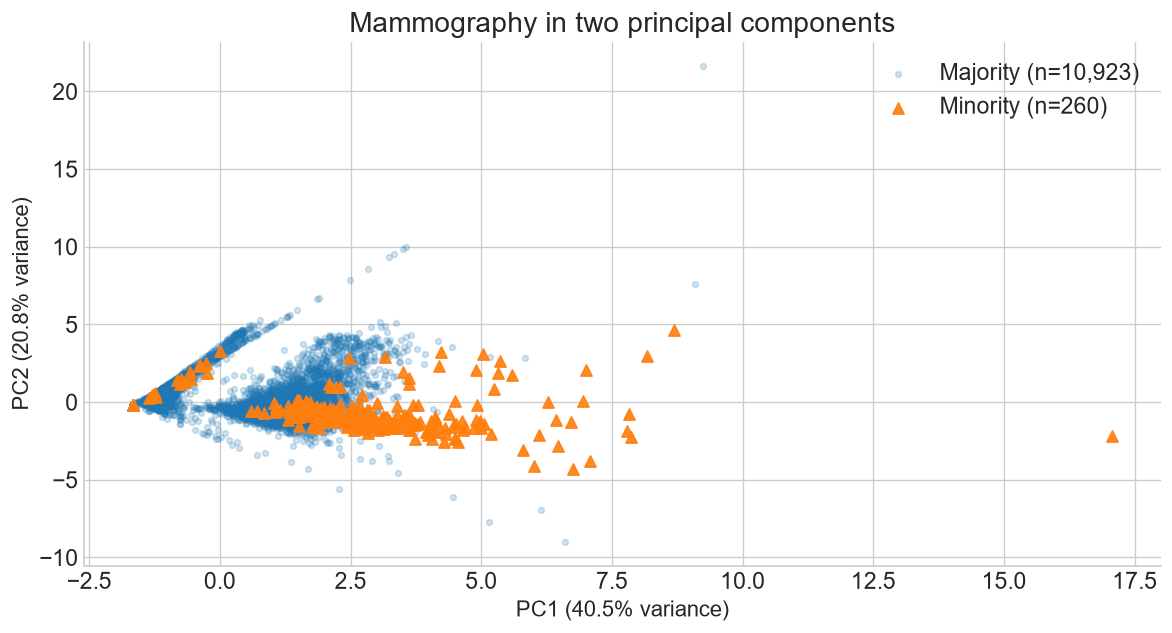

In [ ]:
#| echo: false
#| fig-height: 4.7

m_pca = PCA(n_components=2)
m_pcs = m_pca.fit_transform(StandardScaler().fit_transform(X_mammography))
fig, ax = plt.subplots(figsize=(10, 5.5))
for label, marker, color in [(0, "o", BLUE), (1, "^", ORANGE)]:
    mask = y_mammography == label
    ax.scatter(
        m_pcs[mask, 0], m_pcs[mask, 1], marker=marker, color=color,
        s=12 if label == 0 else 45, alpha=0.2 if label == 0 else 0.9,
        label=f"{'Majority' if label == 0 else 'Minority'} (n={mask.sum():,})",
    )
ax.set_xlabel(f"PC1 ({m_pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({m_pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title("Mammography in two principal components")
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
X_mammography.groupby(y_mammography).agg(["mean", "std"]).round(2)


feature_1       feature_2        ... feature_5       feature_6      
              mean   std      mean   std  ...      mean   std      mean   std
minority                                  ...                                
0            -0.02  0.98      0.00  1.01  ...     -0.07  0.71     -0.03  0.99
1             0.77  1.30     -0.12  0.52  ...      3.06  3.47      1.10  0.68

[2 rows x 12 columns]

# One train/validation split for all exercises

Use a 70% training / 30% validation split and the same tree settings throughout.

- Fit preprocessing, class weighting, and sampling using training rows only.
- Treat validation as a development set: compare methods here, but reserve a separate test set for a final generalization claim. 

In [ ]:
m_X_train, m_X_valid, m_y_train, m_y_valid = train_test_split(
    X_mammography, y_mammography, test_size=0.30,
    stratify=y_mammography, random_state=42,
)
m_tree_params = dict(max_depth=5, min_samples_leaf=5, random_state=42)  # Use `m_tree_params` for every exercise.

def mammography_scores(model, X_valid, y_valid):  # This helper function reports accuracy, balanced accuracy, minority precision/recall/F1, and false positives/negatives on the original validation rows.
    predicted = model.predict(X_valid)
    _, fp, fn, _ = confusion_matrix(y_valid, predicted, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_valid, predicted),
        "Balanced accuracy": balanced_accuracy_score(y_valid, predicted),
        "Precision": precision_score(y_valid, predicted, zero_division=0),
        "Recall": recall_score(y_valid, predicted, zero_division=0),
        "F1": f1_score(y_valid, predicted, zero_division=0),
        "FP": fp, "FN": fn,
    }


# Exercise 1: a scikit-learn decision-tree pipeline

Build and fit an **unweighted** decision tree using the original class distribution.

- How many positives are missed?
- Rank the fitted tree's `feature_importances_`: which features dominate?

In [ ]:
# Fill in the estimator and uncomment: use DecisionTreeClassifier(**m_tree_params).
# m_baseline = Pipeline([("tree", ...)])
# m_baseline.fit(m_X_train, m_y_train)
# mammography_scores(m_baseline, m_X_valid, m_y_valid)
# TODO: rank m_baseline.named_steps["tree"].feature_importances_
#       using m_X_train.columns as the feature names.


# Exercise 2: give the classes balanced weights

Clone the baseline and set `tree__class_weight="balanced"`, then refit on the **same original training rows**. 

- Did minority F1 improve? Did the important features change? Class weighting does not guarantee a better result on every metric.


In [ ]:
# Fill in the class weight and uncomment.
# m_weighted = clone(m_baseline).set_params(tree__class_weight=...)
# m_weighted.fit(m_X_train, m_y_train)
# mammography_scores(m_weighted, m_X_valid, m_y_valid)


# Exercise 3: an imblearn pipeline with SMOTE

Chain `StandardScaler`, `SMOTE`, and an **unweighted** decision tree. 

- Use `random_state=42` for SMOTE and the same `m_tree_params` as before.
- Fit the whole pipeline on training data and compare with Exercises 1 and 2.


In [ ]:
# Fill in SMOTE(random_state=42), then uncomment and fit.
# m_smote = ImbPipeline([
#     ("scaler", StandardScaler()),
#     ("sampler", ...),
#     ("tree", DecisionTreeClassifier(**m_tree_params)),
# ])
# m_smote.fit(m_X_train, m_y_train)
# mammography_scores(m_smote, m_X_valid, m_y_valid)


# Exercise 4: SMOTE with and without scaling

Disable the SMOTE pipeline's scaler with `"passthrough"`, refit, and compare with scaled SMOTE.

- Repeat after changing feature units using the factors below.
- Why can scaling change SMOTE even though the classifier is a tree? Can scaling *after* SMOTE repair its neighbor choices?


In [ ]:
# Fill in "passthrough", then fit and evaluate as above.
# m_unscaled = clone(m_smote).set_params(scaler=...)

# Repeat with changed units: fit on train_units, evaluate on valid_units.
m_units = [1, 10, 100, 0.01, 0.001, 1000]
m_X_train_units = m_X_train * m_units
m_X_valid_units = m_X_valid * m_units


# Exercise 5: Borderline-SMOTE

Clone the **scaled** SMOTE pipeline and replace its sampler with `BorderlineSMOTE(random_state=42)` ([`BorderlineSMOTE`](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.BorderlineSMOTE.html)).

- Keep the scaling, tree, and split fixed. Compare with ordinary scaled SMOTE.
- Which errors change, and does F1 improve? Explain why concentrating on boundary observations might help or amplify overlap and noise.

In [ ]:
# Fill in BorderlineSMOTE(random_state=42), then fit and evaluate.
# m_borderline = clone(m_smote).set_params(sampler=...)
# TODO: compare all five models using the same validation set.


# Exercise Solution

<details>
<summary>Show the solution</summary>

```python

m_baseline = Pipeline([("tree", DecisionTreeClassifier(**m_tree_params))])
m_weighted = clone(m_baseline).set_params(tree__class_weight="balanced")
m_smote = ImbPipeline([
    ("scaler", StandardScaler()),
    ("sampler", SMOTE(random_state=42)),
    ("tree", DecisionTreeClassifier(**m_tree_params)),
])
m_unscaled = clone(m_smote).set_params(scaler="passthrough")
m_borderline = clone(m_smote).set_params(sampler=BorderlineSMOTE(random_state=42))
m_models = {
    "Tree": m_baseline, "Weighted tree": m_weighted,
    "SMOTE": m_smote, "SMOTE without scaling": m_unscaled,
    "Borderline-SMOTE": m_borderline,
}
for model in m_models.values():
    model.fit(m_X_train, m_y_train)
display(pd.DataFrame({
    name: mammography_scores(model, m_X_valid, m_y_valid)
    for name, model in m_models.items()
}).T.round(3))
display(pd.DataFrame({
    name: m_models[name].named_steps["tree"].feature_importances_
    for name in ["Tree", "Weighted tree"]
}, index=m_X_train.columns).sort_values("Tree", ascending=False).round(3))
# Repeat the SMOTE comparison with the feature factors from Exercise 4.
m_unit_models = {}
m_unit_scores = {}
for name in ["SMOTE", "SMOTE without scaling"]:
    model = clone(m_models[name]).fit(m_X_train_units, m_y_train)
    m_unit_models[name] = model
    m_unit_scores[name] = mammography_scores(model, m_X_valid_units, m_y_valid)
display(pd.DataFrame(m_unit_scores).T.round(3))
pd.DataFrame({
    name: m_unit_models[name].named_steps["tree"].feature_importances_
    for name in ["SMOTE without scaling"]
}, index=m_X_train.columns).sort_values("SMOTE without scaling", ascending=False).round(3)


```

</details>


# References